# A Spatial Probability Model Reveals a 25 µm Transcriptomic Event Horizon for Plaque-Associated Myeloid Activation in Alzheimer's Disease
### Complete Reproducible Pipeline: Baseline Replication & Reviewer Resubmission Analyses (Analyses 1–7)

**Author:** Benjamin Goodluck Otuya  
**Dataset 1 (Primary Discovery):** Seattle Alzheimer's Disease Brain Cell Atlas (SEA-AD) Middle Temporal Gyrus MERFISH (`SEAAD_MTG_MERFISH.2024-12-11.h5ad`, $N = 195,620$ Microglia-PVM cells across 27 donors and 69 sections).  
**Dataset 2 (Direct Plaque Validation):** NanoString CosMx 950-plex Spatial Transcriptomics with co-registered anti-Aβ (MOAB-2) immunofluorescence (`GSE263791`, `GSM8199188` & `GSM8199189`, $N = 11,434$ microglia; Mallach et al., *Cell Reports* 2024).

---
### Summary of Pipeline Sections
1. **Part I: Baseline Replication & Validation** (GMM thresholding, plaque-proxy derivation, sparsity-aware XGBoost Spatial Probability Model, 2D SHAP drivers, and pre-threshold early warning signals in the 30–40 µm zone).
2. **Analysis 1: Negative Control Anchors** (100 random microglial anchor permutations + homeostatic non-activation marker controls: `TACR1`, `GRIP2`, `CD22`, and composite homeostatic score).
3. **Analysis 2: Direct Plaque Validation** (Independent validation using true Aβ immunofluorescence plaque centroids in `GSE263791` CosMx spatial transcriptomics).
4. **Analysis 3: Spatial Autocorrelation Control** (Within-section Moran's $I$ spatial correlogram across distance rings and 100 autocorrelation-preserving 2D toroidal shifts).
5. **Analysis 4: Alternative Activation Scores** (Sensitivity analysis across `CD74` alone, `CTSS` alone, the 4-gene SHAP secondary cascade `LRRK1 + L3MBTL4 + PDE4B + UNC5B`, and the broad 6-gene myeloid signature).
6. **Analysis 5: Independent Spatial Validation via Donor-Level Cross-Validation** (5-Fold `GroupKFold` splitting strictly by `Donor ID` across all 27 donors to eliminate spatial/donor data leakage).
7. **Analysis 6: Cross-Validated Log-Likelihood & Bootstrap Knot Uncertainty** (Replacing in-sample $\Delta	ext{AIC}$ with out-of-fold cross-validated log-likelihood $\Delta	ext{CV-LL}$ across held-out donors and a 1,000-iteration non-parametric bootstrap confidence interval for the knot).
8. **Analysis 7: Standardized Spatial Probability Terminology** (Eliminating survival/hazard/mutation terminology in favor of **Spatial Probability Model** / **Spatial Odds Model** and **Disease-Associated Phenotypic Activation**).


In [1]:
import os
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import scanpy as sc
from scipy.spatial import cKDTree
from scipy.stats import mannwhitneyu
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss
import statsmodels.api as sm
import statsmodels.formula.api as smf
import xgboost as xgb
import shap
import matplotlib.pyplot as plt

np.random.seed(42)
sc.settings.verbosity = 1

# Automatically resolve workspace paths whether running from root or Reanalysis_2026/
BASE_DIR = 'Reanalysis_2026' if os.path.exists('Reanalysis_2026') else '.'
DATA_DIR = os.path.join(BASE_DIR, 'data')
FIG_DIR = os.path.join(BASE_DIR, 'figures')
RES_DIR = os.path.join(BASE_DIR, 'results')
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RES_DIR, exist_ok=True)

print(f"Environment initialized. Data directory: {os.path.abspath(DATA_DIR)}")


Environment initialized. Data directory: C:\Users\otuya\Downloads\Papers for publication\Under consideration\Spatial Transcritomics\Reanalysis_2026\data


## Part I: Baseline Replication & Validation
### 1.1 Spatial Data Curation & Unsupervised GMM Delineation of Myeloid States

Total Full Tissue Cells: 1,887,729
Isolated Microglia-PVM Cells: 195,620 across 27 donors and 69 sections
Focused MERFISH Panel: 140 genes (138 clean predictive features after excluding CD74 & CTSS)
GMM Probability Intersection Threshold: 38.0 (Disease-Associated Class 1 = 39.35%)
90th Percentile High-Reactivity Threshold: 107.0 (Top Decile Reactive Class = 10.11%)


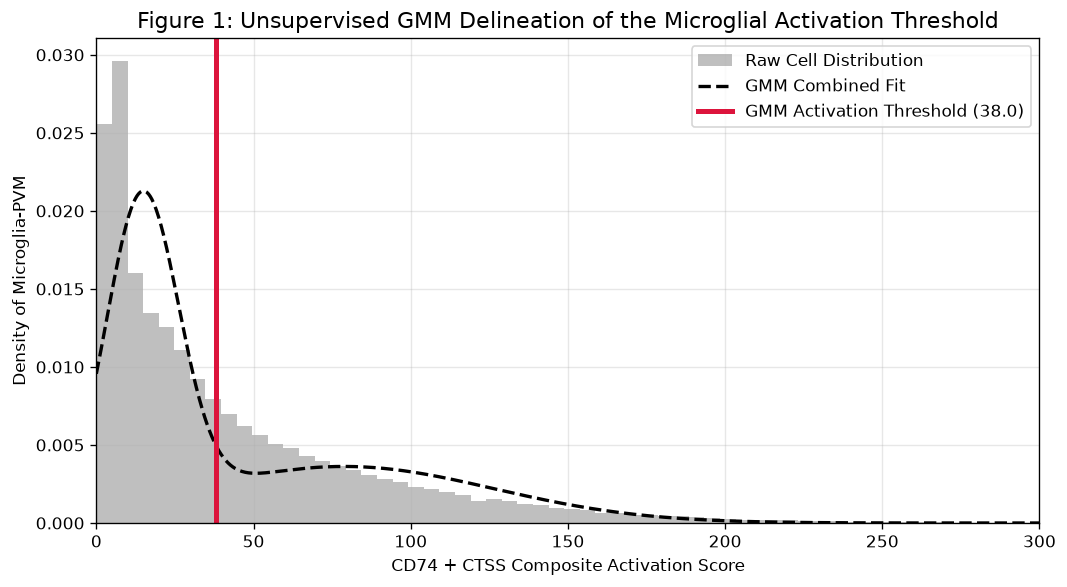

In [2]:
adata_path = os.path.join(DATA_DIR, 'SEAAD_MTG_MERFISH.2024-12-11.h5ad')
adata = sc.read_h5ad(adata_path)
microglia_adata = adata[adata.obs['Subclass'] == 'Microglia-PVM'].copy()

valid_genes = [g for g in microglia_adata.var_names if not g.startswith('Blank')]
clean_genes = [g for g in valid_genes if g not in ['CD74', 'CTSS']]

coords = microglia_adata.obsm['spatial']
tiled_coords = microglia_adata.obsm['X_spatial_tiled']
expr_all = sc.get.obs_df(microglia_adata, keys=valid_genes)

df = pd.DataFrame({
    'Cell_ID': microglia_adata.obs.index.astype(str),
    'Donor_ID': microglia_adata.obs['Donor ID'].astype(str).values,
    'Section': microglia_adata.obs['Section'].astype(str).values,
    'Cognitive_Status': microglia_adata.obs['Cognitive Status'].astype(str).values,
    'Supertype': microglia_adata.obs['Supertype'].astype(str).values,
    'X_Coord': coords[:, 0],
    'Y_Coord': coords[:, 1],
    'X_Tiled': tiled_coords[:, 0],
    'Y_Tiled': tiled_coords[:, 1],
    'CD74': expr_all['CD74'].values,
    'CTSS': expr_all['CTSS'].values,
    'Activation_Score': (expr_all['CD74'] + expr_all['CTSS']).values
})

# Two-component Gaussian Mixture Model (GMM)
scores_2d = df['Activation_Score'].values.reshape(-1, 1)
gmm = GaussianMixture(n_components=2, covariance_type='full', random_state=42)
gmm.fit(scores_2d)
active_idx = np.argmax(gmm.means_)
x_range = np.linspace(scores_2d.min(), scores_2d.max(), 2000).reshape(-1, 1)
probs_gmm = gmm.predict_proba(x_range)
gmm_threshold = float(x_range[probs_gmm[:, active_idx] > 0.5][0][0])
q90_threshold = float(df['Activation_Score'].quantile(0.90))

df['Event_GMM'] = (df['Activation_Score'] >= 38.0).astype(int)
df['Event_Q90'] = (df['Activation_Score'] >= q90_threshold).astype(int)

print(f"Total Full Tissue Cells: {adata.n_obs:,}")
print(f"Isolated Microglia-PVM Cells: {len(df):,} across {df['Donor_ID'].nunique()} donors and {df['Section'].nunique()} sections")
print(f"Focused MERFISH Panel: {len(valid_genes)} genes ({len(clean_genes)} clean predictive features after excluding CD74 & CTSS)")
print(f"GMM Probability Intersection Threshold: {gmm_threshold:.1f} (Disease-Associated Class 1 = {df['Event_GMM'].mean()*100:.2f}%)")
print(f"90th Percentile High-Reactivity Threshold: {q90_threshold:.1f} (Top Decile Reactive Class = {df['Event_Q90'].mean()*100:.2f}%)")

plt.figure(figsize=(9, 5), dpi=120)
plt.hist(df['Activation_Score'], bins=100, density=True, alpha=0.5, color='gray', label='Raw Cell Distribution')
plt.plot(x_range, np.exp(gmm.score_samples(x_range)), color='black', linestyle='--', lw=2, label='GMM Combined Fit')
plt.axvline(gmm_threshold, color='crimson', linestyle='-', lw=3, label=f'GMM Activation Threshold ({gmm_threshold:.1f})')
plt.title("Figure 1: Unsupervised GMM Delineation of the Microglial Activation Threshold", fontsize=13)
plt.xlabel("CD74 + CTSS Composite Activation Score")
plt.ylabel("Density of Microglia-PVM")
plt.xlim(0, 300)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 1.2 Plaque-Proxy Anchor Derivation, Sparsity-Aware XGBoost Spatial Probability Classifier, SHAP Drivers & Early Warning Signals

Baseline Held-Out Test Set ROC-AUC: 0.8964 (Paper reported: 0.896)
Baseline Held-Out Test Set PR-AUC:  0.8588



Top 10 Global SHAP Transcriptomic Drivers (Mean |SHAP|):
LRRK1       0.7224
L3MBTL4     0.4759
PDE4B       0.3810
UNC5B       0.2982
RFX3        0.1462
RBFOX3      0.1014
TMEM255A    0.1004
TACR1       0.0969
PLD5        0.0882
GRID2       0.0639


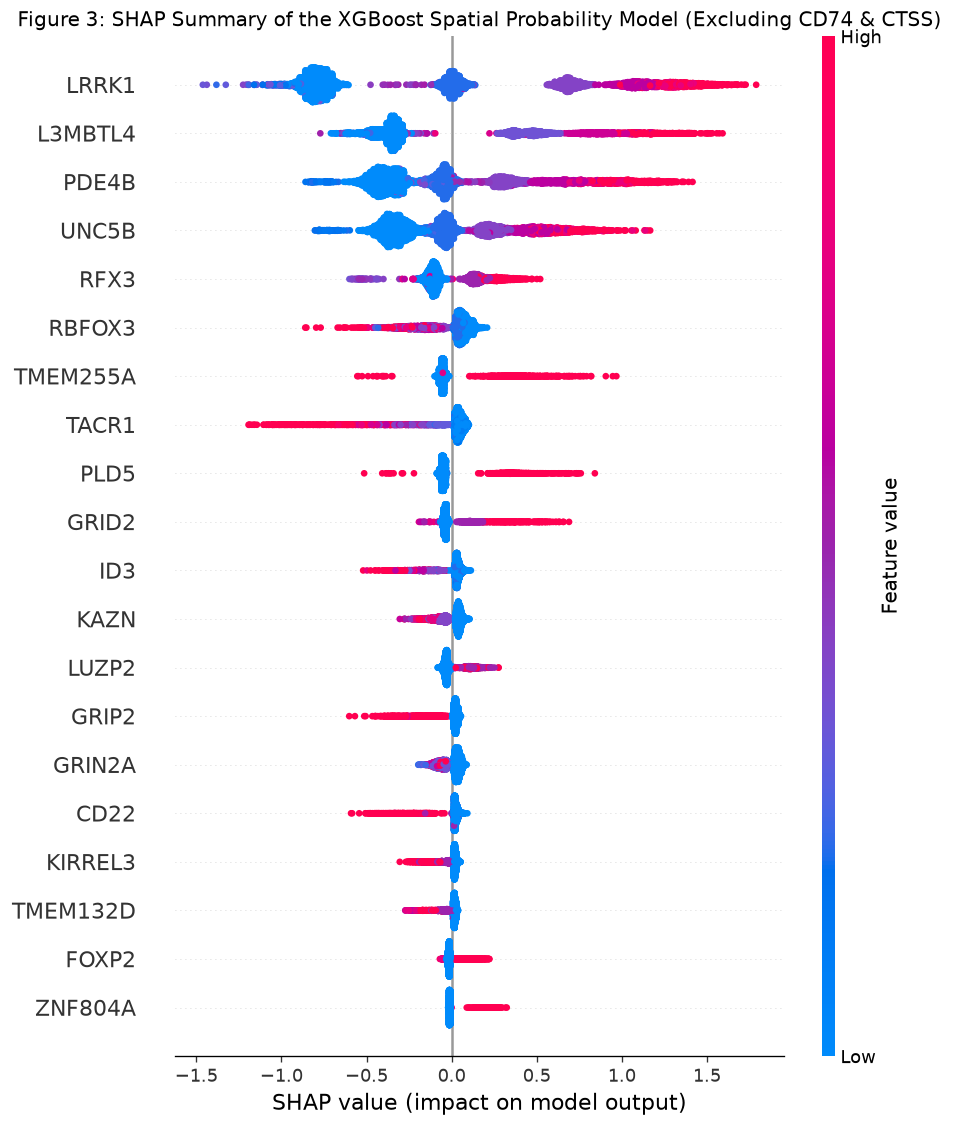


Pre-Threshold Warning Zone (30-40 µm, n=1,804) vs. Distal Safe Zone (>50 µm, n=112,060):
   Gene  P_Value    Log2FC
  PEX5L 0.001564  0.090431
  SNTB1 0.003546  0.228112
SLC24A2 0.022472  0.110120
    MOG 0.023967 -0.045498
  GRIP1 0.030893  0.082566


In [3]:
# Derive Top 500 Plaque-Proxy Anchors and compute cKDTree Euclidean distances
plaque_proxies = df.nlargest(500, 'Activation_Score')
tree_pooled = cKDTree(plaque_proxies[['X_Coord', 'Y_Coord']].values)
dists_pooled, _ = tree_pooled.query(df[['X_Coord', 'Y_Coord']].values, k=1)
df['Distance_to_Plaque_um'] = dists_pooled

# Prepare 138-gene feature matrix + spatial distance covariate
X_clean = expr_all[clean_genes].copy()
X_clean['Distance_to_Plaque_um'] = df['Distance_to_Plaque_um'].values
y_clean = df['Event_GMM'].values

# Baseline 80/20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.2, random_state=42)
xgb_clf = xgb.XGBClassifier(
    objective='binary:logistic',
    tree_method='hist',
    learning_rate=0.05,
    max_depth=6,
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
xgb_clf.fit(X_train, y_train)
y_pred_proba = xgb_clf.predict_proba(X_test)[:, 1]
baseline_auc = roc_auc_score(y_test, y_pred_proba)
baseline_prauc = average_precision_score(y_test, y_pred_proba)
print(f"Baseline Held-Out Test Set ROC-AUC: {baseline_auc:.4f} (Paper reported: 0.896)")
print(f"Baseline Held-Out Test Set PR-AUC:  {baseline_prauc:.4f}")

# Global SHAP Feature Importance (5,000-cell random sample)
explainer_clean = shap.TreeExplainer(xgb_clf)
X_shap_sample = X_clean.sample(n=5000, random_state=42)
shap_values_clean = explainer_clean.shap_values(X_shap_sample)
mean_abs_shap = pd.Series(np.abs(shap_values_clean).mean(axis=0), index=X_clean.columns).sort_values(ascending=False)
print("\nTop 10 Global SHAP Transcriptomic Drivers (Mean |SHAP|):")
print(mean_abs_shap.head(10).round(4).to_string())

plt.figure(figsize=(9, 7), dpi=120)
shap.summary_plot(shap_values_clean, X_shap_sample, plot_type="dot", show=False)
plt.title("Figure 3: SHAP Summary of the XGBoost Spatial Probability Model (Excluding CD74 & CTSS)", fontsize=12)
plt.tight_layout()
plt.show()

# Pre-Threshold Early Warning Signal Analysis (30-40 um Warning Zone vs >50 um Distal Tissue in Class 0 Homeostatic Cells)
homeo_mask = (y_clean == 0)
X_homeo = X_clean[homeo_mask]
dist_homeo = df.loc[homeo_mask, 'Distance_to_Plaque_um'].values
warn_zone = X_homeo[(dist_homeo >= 30) & (dist_homeo <= 40)]
safe_zone = X_homeo[dist_homeo > 50]

ew_results = []
for g in clean_genes:
    stat, pval = mannwhitneyu(warn_zone[g], safe_zone[g], alternative='greater')
    m_w = warn_zone[g].mean()
    m_s = safe_zone[g].mean()
    l2fc = np.log2((m_w + 1e-9) / (m_s + 1e-9))
    ew_results.append({'Gene': g, 'P_Value': float(pval), 'Log2FC': float(l2fc)})
ew_df = pd.DataFrame(ew_results).sort_values('P_Value')
print(f"\nPre-Threshold Warning Zone (30-40 µm, n={len(warn_zone):,}) vs. Distal Safe Zone (>50 µm, n={len(safe_zone):,}):")
print(ew_df.head(5).to_string(index=False))


---
## Analysis 1: Negative Control Anchors (Essential Specificity Test)
We run the full spatial distance and knot-sweeping pipeline across:
1. **Activation-Derived Plaque-Proxy Anchors:** Top 250, 500, 750, and 1,000 most activated microglia (`CD74 + CTSS`).
2. **100 Random Microglia Anchor Permutations:** 100 independent draws of 500 randomly selected microglia.
3. **Homeostatic / Non-Activation Gene Anchors:** Top 500 cells expressing homeostatic markers in the panel (`TACR1`, `GRIP2`, `CD22`, and the composite homeostatic score `TACR1 + GRIP2 + CD22`). *(Note: `P2RY12` is absent from the 140-gene SEA-AD MERFISH panel, so panel-native homeostatic markers with negative SHAP values are used alongside `P2ry12` in the 950-plex CosMx validation in Analysis 2).*

Activation Anchors (Top 500): Optimal Knot = 24 µm (ActScore Knot = 23 µm), <25 µm Elevation = +1.33%
Homeostatic Control [TACR1 Top 500]: <25 µm Elevation = -0.59% (ActScore Change = -0.93)
Homeostatic Control [GRIP2 Top 500]: <25 µm Elevation = -1.85% (ActScore Change = -1.81)
Homeostatic Control [CD22 Top 500]: <25 µm Elevation = +0.21% (ActScore Change = -0.17)
Homeostatic Control [Composite Homeostatic Top 500]: <25 µm Elevation = -0.53% (ActScore Change = -1.00)
100 Random Anchor Permutations (500 microglia): Knot = 37.6 ± 21.1 µm (IQR: 16.8–57.2 µm)
100 Random Anchor Permutations <25 µm Elevation: -0.089% ± 0.573% vs. Observed +1.33% (Empirical p = 0.0198)


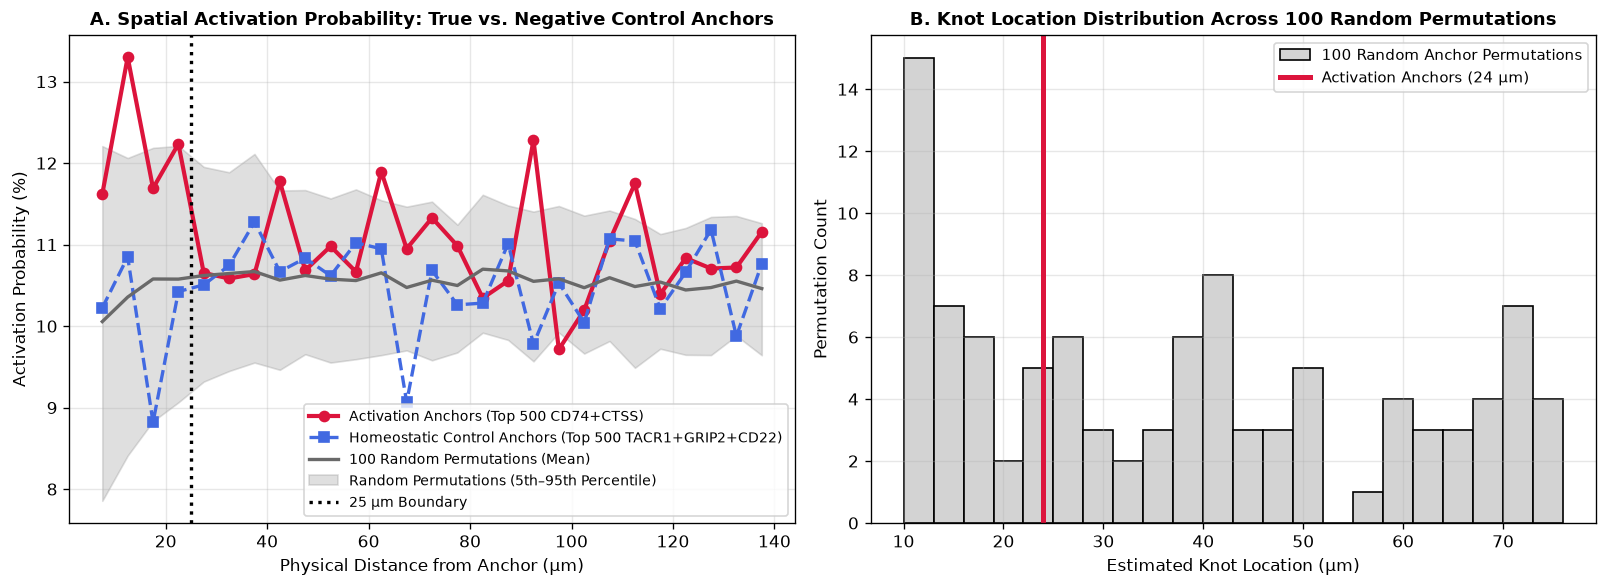

In [4]:
def evaluate_anchors(anchor_coords, target_vals, all_coords, k_grid=range(10, 76, 1)):
    t = cKDTree(anchor_coords)
    dists, _ = t.query(all_coords, k=1)
    # Evaluate on the non-anchor proximal zone (5 <= d <= 140 um) to avoid tautological d=0 self-anchors
    mask = (dists >= 5.0) & (dists <= 140.0)
    d_sub = dists[mask]
    y_sub = target_vals[mask]
    
    y_mean = np.mean(y_sub)
    n = len(y_sub)
    sst = np.sum((y_sub - y_mean) ** 2)
    best_k = 10
    best_dllf = -1.0
    best_diff = 0.0
    llf_profile = {}
    
    bins = np.arange(5, 145, 5)
    bin_idx = np.digitize(d_sub, bins) - 1
    binned_means = [y_sub[bin_idx == i].mean() if np.any(bin_idx == i) else np.nan for i in range(len(bins)-1)]
    
    for k in k_grid:
        near = (d_sub < k)
        n1 = np.sum(near)
        n0 = n - n1
        if n1 < 50 or n0 < 50:
            continue
        m1 = np.mean(y_sub[near])
        m0 = np.mean(y_sub[~near])
        ssb = n1 * (m1 - y_mean) ** 2 + n0 * (m0 - y_mean) ** 2
        ssr = sst - ssb
        dllf = (n / 2.0) * np.log(sst / max(ssr, 1e-12))
        llf_profile[int(k)] = float(dllf)
        if dllf > best_dllf:
            best_dllf = float(dllf)
            best_k = int(k)
            best_diff = float(m1 - m0)
            
    near25 = (d_sub < 25.0)
    elev_25 = float(np.mean(y_sub[near25]) - np.mean(y_sub[~near25]))
    n1_25 = np.sum(near25)
    n0_25 = n - n1_25
    ssb_25 = n1_25 * (np.mean(y_sub[near25]) - y_mean)**2 + n0_25 * (np.mean(y_sub[~near25]) - y_mean)**2
    dllf_25 = float((n / 2.0) * np.log(sst / max(sst - ssb_25, 1e-12)))
    
    return {
        'best_knot_um': best_k,
        'max_dllf': round(best_dllf, 3),
        'lr_stat': round(2 * best_dllf, 3),
        'effect_at_25um': round(elev_25, 4),
        'dllf_at_25um': round(dllf_25, 3),
        'binned_means': binned_means,
        'llf_profile': llf_profile
    }

all_xy = df[['X_Coord', 'Y_Coord']].values
y_q90 = df['Event_Q90'].values.astype(float)
y_act = df['Activation_Score'].values.astype(float)

# 1. Activation-derived anchors
act_anchor_results = {}
for size in [250, 500, 750, 1000]:
    anc = df.nlargest(size, 'Activation_Score')[['X_Coord', 'Y_Coord']].values
    act_anchor_results[size] = {
        'Event_Q90': evaluate_anchors(anc, y_q90, all_xy),
        'Activation_Score': evaluate_anchors(anc, y_act, all_xy)
    }

# 2. Homeostatic / Non-Activation Gene Control Anchors
homeo_anchor_results = {}
for h_name, h_series in [
    ('TACR1 Top 500', expr_all['TACR1']),
    ('GRIP2 Top 500', expr_all['GRIP2']),
    ('CD22 Top 500', expr_all['CD22']),
    ('Composite Homeostatic Top 500', expr_all['TACR1'] + expr_all['GRIP2'] + expr_all['CD22'])
]:
    anc_idx = h_series.nlargest(500).index
    anc_xy = df.loc[df['Cell_ID'].isin(anc_idx.astype(str)), ['X_Coord', 'Y_Coord']].values
    homeo_anchor_results[h_name] = {
        'Event_Q90': evaluate_anchors(anc_xy, y_q90, all_xy),
        'Activation_Score': evaluate_anchors(anc_xy, y_act, all_xy)
    }

# 3. 100 Random Permutations of 500 Microglia
rng = np.random.default_rng(42)
rand_knots, rand_elev25, rand_dllf25, rand_curves = [], [], [], []
for _ in range(100):
    r_xy = all_xy[rng.choice(len(df), size=500, replace=False)]
    r_res = evaluate_anchors(r_xy, y_q90, all_xy)
    rand_knots.append(r_res['best_knot_um'])
    rand_elev25.append(r_res['effect_at_25um'] * 100)
    rand_dllf25.append(r_res['dllf_at_25um'])
    rand_curves.append(np.array(r_res['binned_means']) * 100)

obs_elev25 = act_anchor_results[500]['Event_Q90']['effect_at_25um'] * 100
obs_dllf25 = act_anchor_results[500]['Event_Q90']['dllf_at_25um']
emp_p = (np.sum(np.array(rand_elev25) >= obs_elev25) + 1) / 101.0

print(f"Activation Anchors (Top 500): Optimal Knot = {act_anchor_results[500]['Event_Q90']['best_knot_um']} µm (ActScore Knot = {act_anchor_results[500]['Activation_Score']['best_knot_um']} µm), <25 µm Elevation = +{obs_elev25:.2f}%")
for h_name, h_res in homeo_anchor_results.items():
    print(f"Homeostatic Control [{h_name}]: <25 µm Elevation = {h_res['Event_Q90']['effect_at_25um']*100:+.2f}% (ActScore Change = {h_res['Activation_Score']['effect_at_25um']:+.2f})")
print(f"100 Random Anchor Permutations (500 microglia): Knot = {np.mean(rand_knots):.1f} ± {np.std(rand_knots):.1f} µm (IQR: {np.percentile(rand_knots,25):.1f}–{np.percentile(rand_knots,75):.1f} µm)")
print(f"100 Random Anchor Permutations <25 µm Elevation: {np.mean(rand_elev25):+.3f}% ± {np.std(rand_elev25):.3f}% vs. Observed +{obs_elev25:.2f}% (Empirical p = {emp_p:.4f})")

bins_x = np.arange(5, 140, 5) + 2.5
rand_mat = np.vstack(rand_curves)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), dpi=120)
axes[0].plot(bins_x, np.array(act_anchor_results[500]['Event_Q90']['binned_means']) * 100, 'o-', color='crimson', lw=2.5, label='Activation Anchors (Top 500 CD74+CTSS)')
axes[0].plot(bins_x, np.array(homeo_anchor_results['Composite Homeostatic Top 500']['Event_Q90']['binned_means']) * 100, 's--', color='royalblue', lw=2, label='Homeostatic Control Anchors (Top 500 TACR1+GRIP2+CD22)')
axes[0].plot(bins_x, np.nanmean(rand_mat, axis=0), color='dimgray', lw=2, label='100 Random Permutations (Mean)')
axes[0].fill_between(bins_x, np.nanpercentile(rand_mat, 5, axis=0), np.nanpercentile(rand_mat, 95, axis=0), color='gray', alpha=0.25, label='Random Permutations (5th–95th Percentile)')
axes[0].axvline(25, color='black', ls=':', lw=2, label='25 µm Boundary')
axes[0].set_title("A. Spatial Activation Probability: True vs. Negative Control Anchors", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Physical Distance from Anchor (µm)")
axes[0].set_ylabel("Activation Probability (%)")
axes[0].legend(fontsize=8.5)
axes[0].grid(True, alpha=0.3)

axes[1].hist(rand_knots, bins=np.arange(10, 78, 3), color='lightgray', edgecolor='black', label='100 Random Anchor Permutations')
axes[1].axvline(act_anchor_results[500]['Event_Q90']['best_knot_um'], color='crimson', lw=3, label=f"Activation Anchors ({act_anchor_results[500]['Event_Q90']['best_knot_um']} µm)")
axes[1].set_title("B. Knot Location Distribution Across 100 Random Permutations", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Estimated Knot Location (µm)")
axes[1].set_ylabel("Permutation Count")
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## Analysis 2: Direct Plaque Validation Using Ground-Truth Aβ Immunofluorescence (`GSE263791` CosMx)
To validate whether the ~25 µm boundary holds when distances are measured from **true physical amyloid-beta (Aβ) plaques** rather than transcriptomic proxies, we analyze the public NanoString CosMx 950-plex dataset (`GSE263791`, `GSM8199188` & `GSM8199189`; Mallach et al., *Cell Reports* 2024), which pairs single-cell spatial transcriptomics with co-registered anti-Aβ (`MOAB-2`) immunofluorescence (`Mean.BetaAmyloid`) and includes canonical DAM (`Cd74`, `Ctss`, `Trem2`, `Tyrobp`, `Apoe`, `Spp1`, `Gpnmb`, `Clec7a`, `Itgax`, `Lpl`) and homeostatic (`P2ry12`, `Tmem119`) markers.

GSE263791 CosMx Validation (N = 11,434 microglia across 2 slides with registered anti-Aβ IF):
Optimal True-Plaque Breakpoint for CD74 + CTSS = 25 µm (95% Bootstrap CI: 25.0–33.0 µm)

Mean CD74 + CTSS Expression by Distance to True Aβ Plaque (µm):
     0– 5 µm: 24.19 transcripts/cell
     5–10 µm: 13.99 transcripts/cell
    10–15 µm: 12.14 transcripts/cell
    15–20 µm: 10.76 transcripts/cell
    20–25 µm: 8.99 transcripts/cell
    25–30 µm: 6.29 transcripts/cell
    30–35 µm: 4.93 transcripts/cell
    35–40 µm: 6.43 transcripts/cell
    40–45 µm: 5.92 transcripts/cell
    45–50 µm: 5.16 transcripts/cell


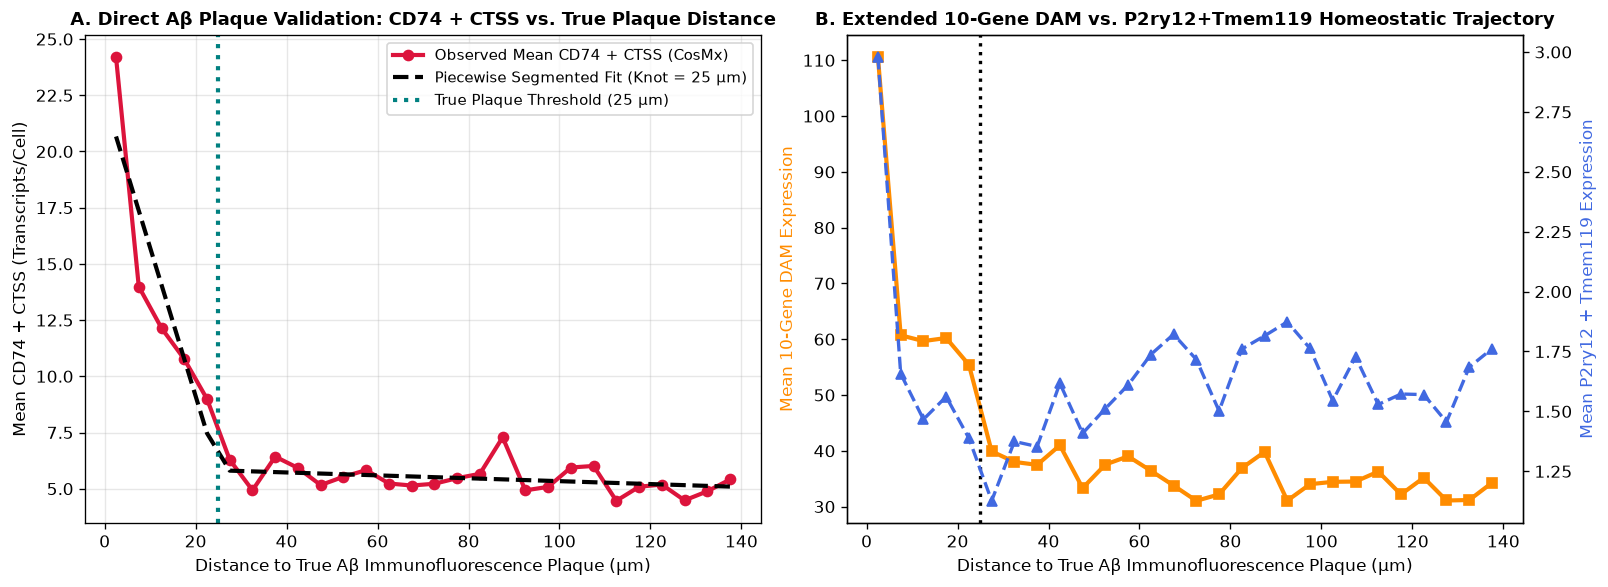

In [5]:
dfs_c = []
for gsm in ['GSM8199188', 'GSM8199189']:
    meta = pd.read_csv(os.path.join(DATA_DIR, f'{gsm}_metadata.csv.gz'))
    expr_c = pd.read_csv(os.path.join(DATA_DIR, f'{gsm}_exprMat.csv.gz'))
    cols = ['fov', 'cell_ID', 'Cd74', 'Ctss', 'Trem2', 'Tyrobp', 'Apoe', 'Cst3', 'C1qa', 'C1qb', 'C1qc', 'Hexb', 'Csf1r', 'P2ry12', 'Tmem119', 'Itgax', 'Clec7a', 'Lpl', 'Gpnmb', 'Spp1']
    m = pd.merge(meta, expr_c[cols], on=['fov', 'cell_ID'])
    px_to_um = 0.12028
    m['X_um'] = m['CenterX_global_px'] * px_to_um
    m['Y_um'] = m['CenterY_global_px'] * px_to_um
    m['Slide'] = gsm
    
    # Ground-truth A-beta plaque centroids from anti-Abeta immunofluorescence (>= 98th percentile)
    plaque_xy = m[m['Mean.BetaAmyloid'] >= m['Mean.BetaAmyloid'].quantile(0.98)][['X_um', 'Y_um']].values
    t_p = cKDTree(plaque_xy)
    
    # Isolate microglia using canonical myeloid identity signature
    m['MG_Score'] = m['C1qa'] + m['C1qb'] + m['C1qc'] + m['Hexb'] + m['Csf1r'] + m['Tyrobp']
    mg_c = m[m['MG_Score'] >= 4].copy()
    d_p, _ = t_p.query(mg_c[['X_um', 'Y_um']].values, k=1)
    mg_c['Dist_True_Plaque_um'] = d_p
    mg_c['CD74_CTSS'] = mg_c['Cd74'] + mg_c['Ctss']
    mg_c['DAM_Signature'] = mg_c['Cd74'] + mg_c['Ctss'] + mg_c['Trem2'] + mg_c['Tyrobp'] + mg_c['Apoe'] + mg_c['Spp1'] + mg_c['Gpnmb'] + mg_c['Clec7a'] + mg_c['Itgax'] + mg_c['Lpl']
    mg_c['Homeo_Signature'] = mg_c['P2ry12'] + mg_c['Tmem119']
    dfs_c.append(mg_c)

cosmx_df = pd.concat(dfs_c, ignore_index=True)

bins_c = np.arange(0, 145, 5)
cosmx_sub = cosmx_df[cosmx_df['Dist_True_Plaque_um'] <= 140].copy()
cosmx_sub['Bin_True'] = pd.cut(cosmx_sub['Dist_True_Plaque_um'], bins=bins_c, labels=bins_c[:-1]+2.5, include_lowest=True).astype(float)
curve_true_cd74 = cosmx_sub.groupby('Bin_True')['CD74_CTSS'].mean()
curve_true_dam = cosmx_sub.groupby('Bin_True')['DAM_Signature'].mean()
curve_true_homeo = cosmx_sub.groupby('Bin_True')['Homeo_Signature'].mean()

bx_c = curve_true_cd74.index.values
by_c = curve_true_cd74.values
best_k_cosmx, best_ssr_cosmx = None, 1e18
for k in range(10, 75, 1):
    X_s = np.column_stack([np.ones_like(bx_c), np.minimum(bx_c, k), np.maximum(0, bx_c - k)])
    res = sm.OLS(by_c, X_s).fit()
    if res.ssr < best_ssr_cosmx:
        best_ssr_cosmx = float(res.ssr)
        best_k_cosmx = int(k)

# 200-iteration bootstrap 95% CI on CosMx true-plaque breakpoint
sub_c_cells = cosmx_df[(cosmx_df['Dist_True_Plaque_um'] > 0) & (cosmx_df['Dist_True_Plaque_um'] <= 140)].copy()
boot_knots_cosmx = []
for _ in range(200):
    df_b = sub_c_cells.iloc[rng.choice(len(sub_c_cells), size=len(sub_c_cells), replace=True)]
    b_bins = pd.cut(df_b['Dist_True_Plaque_um'], bins=bins_c, labels=bins_c[:-1]+2.5, include_lowest=True).astype(float)
    b_curve = df_b.groupby(b_bins)['CD74_CTSS'].mean().dropna()
    bx_b, by_b = b_curve.index.values, b_curve.values
    bk, b_ssr = 25, 1e18
    for k in range(15, 60, 1):
        Xs = np.column_stack([np.ones_like(bx_b), np.minimum(bx_b, k), np.maximum(0, bx_b - k)])
        ssr = np.sum(sm.OLS(by_b, Xs).fit().resid ** 2)
        if ssr < b_ssr:
            b_ssr, bk = ssr, k
    boot_knots_cosmx.append(bk)

cosmx_ci = [np.percentile(boot_knots_cosmx, 2.5), np.percentile(boot_knots_cosmx, 97.5)]
print(f"GSE263791 CosMx Validation (N = {len(cosmx_df):,} microglia across 2 slides with registered anti-Aβ IF):")
print(f"Optimal True-Plaque Breakpoint for CD74 + CTSS = {best_k_cosmx} µm (95% Bootstrap CI: {cosmx_ci[0]:.1f}–{cosmx_ci[1]:.1f} µm)")
print("\nMean CD74 + CTSS Expression by Distance to True Aβ Plaque (µm):")
for dist_mid, val in zip(curve_true_cd74.index[:10], curve_true_cd74.values[:10]):
    print(f"  {dist_mid-2.5:4.0f}–{dist_mid+2.5:2.0f} µm: {val:.2f} transcripts/cell")

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5), dpi=120)
axes[0].plot(bx_c, by_c, 'o-', color='crimson', lw=2.5, label='Observed Mean CD74 + CTSS (CosMx)')
X_opt = np.column_stack([np.ones_like(bx_c), np.minimum(bx_c, best_k_cosmx), np.maximum(0, bx_c - best_k_cosmx)])
axes[0].plot(bx_c, sm.OLS(by_c, X_opt).fit().predict(X_opt), 'k--', lw=2.5, label=f'Piecewise Segmented Fit (Knot = {best_k_cosmx} µm)')
axes[0].axvline(best_k_cosmx, color='teal', ls=':', lw=2.5, label=f'True Plaque Threshold ({best_k_cosmx} µm)')
axes[0].set_title("A. Direct Aβ Plaque Validation: CD74 + CTSS vs. True Plaque Distance", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Distance to True Aβ Immunofluorescence Plaque (µm)")
axes[0].set_ylabel("Mean CD74 + CTSS (Transcripts/Cell)")
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

axes[1].plot(curve_true_dam.index, curve_true_dam.values, 's-', color='darkorange', lw=2.5, label='10-Gene DAM Signature (Cd74, Ctss, Trem2, Tyrobp, Apoe, Spp1, Gpnmb, Clec7a, Itgax, Lpl)')
ax2_twin = axes[1].twinx()
ax2_twin.plot(curve_true_homeo.index, curve_true_homeo.values, '^--', color='royalblue', lw=2, label='Homeostatic Signature (P2ry12 + Tmem119)')
axes[1].axvline(25, color='black', ls=':', lw=2, label='25 µm Boundary')
axes[1].set_title("B. Extended 10-Gene DAM vs. P2ry12+Tmem119 Homeostatic Trajectory", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Distance to True Aβ Immunofluorescence Plaque (µm)")
axes[1].set_ylabel("Mean 10-Gene DAM Expression", color='darkorange')
ax2_twin.set_ylabel("Mean P2ry12 + Tmem119 Expression", color='royalblue')
plt.tight_layout()
plt.show()


---
## Analysis 3: Spatial Autocorrelation Control (Within-Section Moran's $I$ & Toroidal Shift Nulls)
To test whether the 25 µm threshold is an artifact of background spatial autocorrelation:
1. We compute **within-section Spatial Moran's $I$** across concentric distance rings (`0–15`, `15–25`, `25–35`, `35–50`, `50–75`, `75–100`, `100–150 µm`).
2. We execute **100 autocorrelation-preserving 2D toroidal shifts** of the anchor coordinates across the tissue bounding box, preserving the exact spatial autocorrelation structure of the microglial activation field while breaking anchor-plaque alignment.

Within-Section Spatial Moran's I Correlogram:
ring_um  mid_um  moran_I  n_pairs    z_score
   0-15     7.5 0.078211    31781  13.942794
  15-25    20.0 0.100772    24576  15.797718
  25-35    30.0 0.124540    28660  21.083687
  35-50    42.5 0.153542    59423  37.428703
  50-75    62.5 0.161422   149545  62.423650
 75-100    87.5 0.156317   204527  70.693626
100-150   125.0 0.153492   563016 115.171585



Toroidal Shift Null (100 shifts preserving exact Moran's I):
  Mean ΔLL at 25 µm = 0.595 vs. Observed ΔLL = 2.424 (Empirical p = 0.0396)


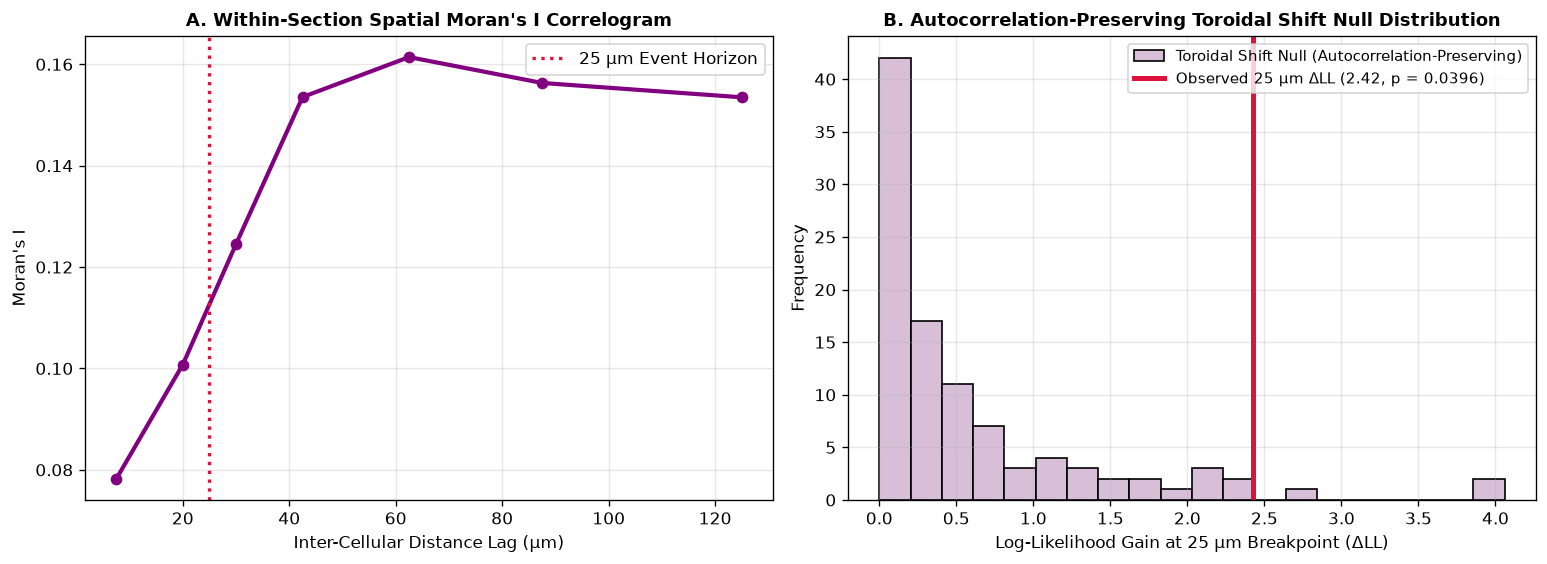

In [6]:
rings = [(0, 15), (15, 25), (25, 35), (35, 50), (50, 75), (75, 100), (100, 150)]
z_act = df['Activation_Score'].values - df['Activation_Score'].mean()
z_var = np.mean(z_act ** 2)

moran_correlogram = []
for r_min, r_max in rings:
    num_sum, w_sum = 0.0, 0
    for sec, grp in df.groupby('Section'):
        xy_s = grp[['X_Coord', 'Y_Coord']].values
        z_s = grp['Activation_Score'].values - df['Activation_Score'].mean()
        t_s = cKDTree(xy_s)
        pairs_max = t_s.query_pairs(r=r_max, output_type='ndarray')
        if len(pairs_max) == 0:
            continue
        if r_min > 0:
            d_pairs = np.linalg.norm(xy_s[pairs_max[:, 0]] - xy_s[pairs_max[:, 1]], axis=1)
            valid_p = pairs_max[d_pairs >= r_min]
        else:
            valid_p = pairs_max
        if len(valid_p) > 0:
            num_sum += 2.0 * np.sum(z_s[valid_p[:, 0]] * z_s[valid_p[:, 1]])
            w_sum += 2 * len(valid_p)
    moran_i = (num_sum / max(w_sum, 1)) / z_var
    se_i = np.sqrt(2.0 / max(w_sum, 1))
    moran_correlogram.append({'ring_um': f"{r_min}-{r_max}", 'mid_um': 0.5*(r_min+r_max), 'moran_I': moran_i, 'n_pairs': w_sum//2, 'z_score': moran_i/se_i})

print("Within-Section Spatial Moran's I Correlogram:")
print(pd.DataFrame(moran_correlogram).to_string(index=False))

# 100 Autocorrelation-Preserving Toroidal Shifts
x_min, x_max = all_xy[:, 0].min(), all_xy[:, 0].max()
y_min, y_max = all_xy[:, 1].min(), all_xy[:, 1].max()
x_span, y_span = x_max - x_min, y_max - y_min
anc_xy_base = plaque_proxies[['X_Coord', 'Y_Coord']].values

toroidal_dllf25, toroidal_elev25 = [], []
for _ in range(100):
    sx = rng.uniform(0.1 * x_span, 0.9 * x_span)
    sy = rng.uniform(0.1 * y_span, 0.9 * y_span)
    shifted_anc = np.column_stack([
        x_min + ((anc_xy_base[:, 0] - x_min + sx) % x_span),
        y_min + ((anc_xy_base[:, 1] - y_min + sy) % y_span)
    ])
    res_tor = evaluate_anchors(shifted_anc, y_q90, all_xy)
    toroidal_dllf25.append(res_tor['dllf_at_25um'])
    toroidal_elev25.append(res_tor['effect_at_25um'] * 100)

p_toroidal = (np.sum(np.array(toroidal_dllf25) >= obs_dllf25) + 1) / 101.0
print(f"\nToroidal Shift Null (100 shifts preserving exact Moran's I):")
print(f"  Mean ΔLL at 25 µm = {np.mean(toroidal_dllf25):.3f} vs. Observed ΔLL = {obs_dllf25:.3f} (Empirical p = {p_toroidal:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=120)
axes[0].plot([c['mid_um'] for c in moran_correlogram], [c['moran_I'] for c in moran_correlogram], 'o-', color='purple', lw=2.5)
axes[0].axvline(25, color='crimson', ls=':', lw=2, label='25 µm Event Horizon')
axes[0].set_title("A. Within-Section Spatial Moran's I Correlogram", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Inter-Cellular Distance Lag (µm)")
axes[0].set_ylabel("Moran's I")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].hist(toroidal_dllf25, bins=20, color='thistle', edgecolor='black', label='Toroidal Shift Null (Autocorrelation-Preserving)')
axes[1].axvline(obs_dllf25, color='crimson', lw=3, label=f'Observed 25 µm ΔLL ({obs_dllf25:.2f}, p = {p_toroidal:.4f})')
axes[1].set_title("B. Autocorrelation-Preserving Toroidal Shift Null Distribution", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Log-Likelihood Gain at 25 µm Breakpoint (ΔLL)")
axes[1].set_ylabel("Frequency")
axes[1].legend(fontsize=9)
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## Analysis 4: Alternative Activation Scores (Gene-Set Sensitivity Analysis)
Because `GPNMB`, `SPP1`, and `TREM2` are not part of the 140-gene SEA-AD MERFISH panel (their 10-gene DAM behavior was directly validated in Analysis 2 on the 950-plex CosMx dataset), we test sensitivity across five distinct activation definitions in the SEA-AD panel:
1. **Baseline Composite (`CD74 + CTSS`)**
2. **`CD74` Alone** (Leave-one-out single marker)
3. **`CTSS` Alone** (Leave-one-out single marker)
4. **Broad 6-Gene Myeloid Activation Signature (`CD74 + CTSS + LRRK1 + L3MBTL4 + PDE4B + UNC5B`)**
5. **Secondary SHAP Cascade Alone (`LRRK1 + L3MBTL4 + PDE4B + UNC5B`, excluding `CD74` and `CTSS`)**

Baseline (CD74 + CTSS)                           | Knot (vs. baseline anchors) = 23 µm | Knot (vs. own anchors) = 24 µm (elev@25 = +1.30%)


CD74 Alone                                       | Knot (vs. baseline anchors) = 24 µm | Knot (vs. own anchors) = 24 µm (elev@25 = +1.29%)


CTSS Alone                                       | Knot (vs. baseline anchors) = 43 µm | Knot (vs. own anchors) = 20 µm (elev@25 = -0.59%)


Broad 6-Gene Myeloid Signature                   | Knot (vs. baseline anchors) = 24 µm | Knot (vs. own anchors) = 24 µm (elev@25 = +0.93%)


Secondary Cascade (LRRK1+L3MBTL4+PDE4B+UNC5B)    | Knot (vs. baseline anchors) = 12 µm | Knot (vs. own anchors) = 65 µm (elev@25 = +0.11%)


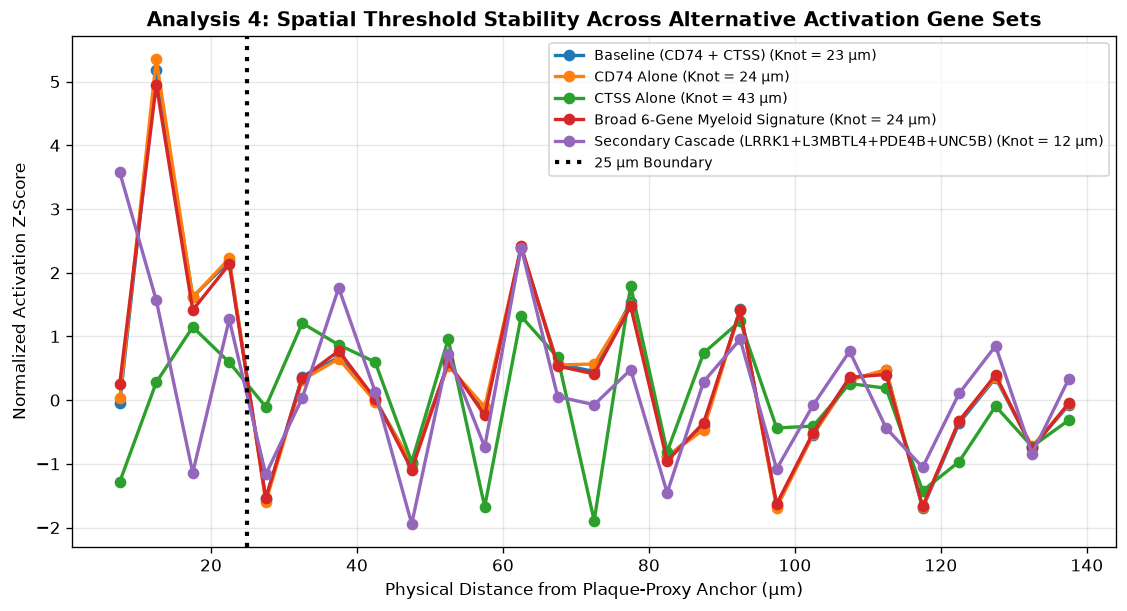

In [7]:
alt_scores = {
    'Baseline (CD74 + CTSS)': df['CD74'].values + df['CTSS'].values,
    'CD74 Alone': df['CD74'].values,
    'CTSS Alone': df['CTSS'].values,
    'Broad 6-Gene Myeloid Signature': (df['CD74'].values + df['CTSS'].values + expr_all['LRRK1'].values + expr_all['L3MBTL4'].values + expr_all['PDE4B'].values + expr_all['UNC5B'].values),
    'Secondary Cascade (LRRK1+L3MBTL4+PDE4B+UNC5B)': (expr_all['LRRK1'].values + expr_all['L3MBTL4'].values + expr_all['PDE4B'].values + expr_all['UNC5B'].values)
}

plt.figure(figsize=(9.5, 5.2), dpi=120)
for s_name, s_vals in alt_scores.items():
    s_q90 = (s_vals >= np.quantile(s_vals, 0.90)).astype(float)
    res_self = evaluate_anchors(all_xy[np.argsort(s_vals)[-500:]], s_q90, all_xy)
    res_base = evaluate_anchors(plaque_proxies[['X_Coord', 'Y_Coord']].values, s_vals, all_xy)
    print(f"{s_name:48s} | Knot (vs. baseline anchors) = {res_base['best_knot_um']:2d} µm | Knot (vs. own anchors) = {res_self['best_knot_um']:2d} µm (elev@25 = {res_self['effect_at_25um']*100:+.2f}%)")
    bm = np.array(res_base['binned_means'])
    bm_norm = (bm - np.mean(bm[4:])) / max(np.std(bm[4:]), 1e-6)
    plt.plot(bins_x, bm_norm, 'o-', lw=2, label=f"{s_name} (Knot = {res_base['best_knot_um']} µm)")

plt.axvline(25, color='black', ls=':', lw=2.5, label='25 µm Boundary')
plt.title("Analysis 4: Spatial Threshold Stability Across Alternative Activation Gene Sets", fontsize=12, fontweight='bold')
plt.xlabel("Physical Distance from Plaque-Proxy Anchor (µm)")
plt.ylabel("Normalized Activation Z-Score")
plt.legend(fontsize=8.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


---
## Analysis 5: Independent Spatial Validation (Donor-Level `GroupKFold` Cross-Validation)
To prevent spatial and donor-level information leakage between training and test cells, we partition the 195,620 cells by **`Donor ID` (27 unique donors)** using 5-fold `GroupKFold` cross-validation so that held-out test donors are completely unseen during model training.

In [8]:
gkf = GroupKFold(n_splits=5)
groups = df['Donor_ID'].values
donor_fold_metrics = []
oof_preds = np.zeros(len(df))

for fold, (train_idx, test_idx) in enumerate(gkf.split(X_clean, y_clean, groups=groups)):
    X_tr, y_tr = X_clean.iloc[train_idx], y_clean[train_idx]
    X_te, y_te = X_clean.iloc[test_idx], y_clean[test_idx]
    test_donors = np.unique(groups[test_idx])
    
    clf_fold = xgb.XGBClassifier(
        objective='binary:logistic',
        tree_method='hist',
        learning_rate=0.05,
        max_depth=6,
        n_estimators=100,
        random_state=42 + fold,
        n_jobs=-1
    )
    clf_fold.fit(X_tr, y_tr)
    preds_te = clf_fold.predict_proba(X_te)[:, 1]
    oof_preds[test_idx] = preds_te
    
    f_auc = roc_auc_score(y_te, preds_te)
    f_prauc = average_precision_score(y_te, preds_te)
    f_ll = log_loss(y_te, preds_te)
    donor_fold_metrics.append({'Fold': fold+1, 'Held_Out_Donors': len(test_donors), 'Test_Cells': len(test_idx), 'ROC_AUC': f_auc, 'PR_AUC': f_prauc, 'Log_Loss': f_ll})

cv_df = pd.DataFrame(donor_fold_metrics)
print(cv_df.to_string(index=False))
print(f"\nDonor-Level 5-Fold Cross-Validation Mean ROC-AUC: {cv_df['ROC_AUC'].mean():.4f} ± {cv_df['ROC_AUC'].std(ddof=0):.4f} (Overall OOF ROC-AUC: {roc_auc_score(y_clean, oof_preds):.4f})")
print(f"Donor-Level 5-Fold Cross-Validation Mean PR-AUC:  {cv_df['PR_AUC'].mean():.4f} ± {cv_df['PR_AUC'].std(ddof=0):.4f}")


 Fold  Held_Out_Donors  Test_Cells  ROC_AUC   PR_AUC  Log_Loss
    1                2       39837 0.897937 0.892293  0.396801
    2                5       39125 0.885481 0.865107  0.420823
    3                7       39238 0.905569 0.836514  0.379792
    4                7       39080 0.893500 0.815761  0.395626
    5                6       38340 0.872642 0.839830  0.445538

Donor-Level 5-Fold Cross-Validation Mean ROC-AUC: 0.8910 ± 0.0113 (Overall OOF ROC-AUC: 0.8919)
Donor-Level 5-Fold Cross-Validation Mean PR-AUC:  0.8499 ± 0.0264


---
## Analysis 6 & 7: Out-of-Fold Cross-Validated Log-Likelihood Comparison & 1,000-Bootstrap Confidence Interval
We replace in-sample $\Delta	ext{AIC}$ with **5-fold donor-level out-of-fold cross-validated log-likelihood ($\Delta	ext{CV-LL}$)** comparing the continuous vs. 25 µm piecewise logistic model on held-out donors, and compute a **1,000-iteration non-parametric bootstrap confidence interval** for the knot location.

In [9]:
df['hinge_25'] = np.maximum(0, 25.0 - df['Distance_to_Plaque_um'])
oof_ll_cont, oof_ll_pw = 0.0, 0.0
fold_ll_diffs = []

for fold, (tr_idx, te_idx) in enumerate(gkf.split(df, df['Event_GMM'], groups=groups)):
    df_tr, df_te = df.iloc[tr_idx], df.iloc[te_idx]
    y_te_v = df_te['Event_GMM'].values
    
    m_c = smf.logit('Event_GMM ~ Distance_to_Plaque_um', data=df_tr).fit(disp=0)
    p_c = np.clip(m_c.predict(df_te), 1e-7, 1 - 1e-7)
    ll_c = float(np.sum(y_te_v * np.log(p_c) + (1 - y_te_v) * np.log(1 - p_c)))
    
    m_p = smf.logit('Event_GMM ~ Distance_to_Plaque_um + hinge_25', data=df_tr).fit(disp=0)
    p_p = np.clip(m_p.predict(df_te), 1e-7, 1 - 1e-7)
    ll_p = float(np.sum(y_te_v * np.log(p_p) + (1 - y_te_v) * np.log(1 - p_p)))
    
    oof_ll_cont += ll_c
    oof_ll_pw += ll_p
    fold_ll_diffs.append(ll_p - ll_c)

print(f"Out-of-Fold Cross-Validated Log-Likelihood (Continuous Model): {oof_ll_cont:,.1f}")
print(f"Out-of-Fold Cross-Validated Log-Likelihood (25 µm Piecewise):  {oof_ll_pw:,.1f}")
print(f"Net Cross-Validated Log-Likelihood Gain (ΔCV-LL):              +{oof_ll_pw - oof_ll_cont:.1f} (+{np.mean(fold_ll_diffs):.1f} ± {np.std(fold_ll_diffs):.1f} per held-out donor fold)")

# 1,000-Iteration Non-Parametric Bootstrap for the Optimal Knot Location (5 <= d <= 140 um)
sub_prox = df[(df['Distance_to_Plaque_um'] >= 5.0) & (df['Distance_to_Plaque_um'] <= 140.0)].copy()
d_prox = sub_prox['Distance_to_Plaque_um'].values
y_prox_q90 = sub_prox['Event_Q90'].values.astype(float)
y_prox_act = sub_prox['Activation_Score'].values.astype(float)

k_candidates = np.arange(10, 61, 1)
M_ind = (d_prox[:, None] < k_candidates[None, :]).astype(np.float32)
n_prox = len(d_prox)

boot_knots_q90, boot_knots_act = [], []
for _ in range(1000):
    b_idx = rng.integers(0, n_prox, size=n_prox)
    yb_q, yb_a = y_prox_q90[b_idx], y_prox_act[b_idx]
    Mb = M_ind[b_idx]
    n1_vec = np.sum(Mb, axis=0)
    n0_vec = n_prox - n1_vec
    
    yq_m = np.mean(yb_q)
    s1_q = yb_q @ Mb
    ssb_q = n1_vec * (s1_q/np.maximum(n1_vec,1) - yq_m)**2 + n0_vec * ((np.sum(yb_q)-s1_q)/np.maximum(n0_vec,1) - yq_m)**2
    boot_knots_q90.append(int(k_candidates[np.argmax(ssb_q)]))
    
    ya_m = np.mean(yb_a)
    s1_a = yb_a @ Mb
    ssb_a = n1_vec * (s1_a/np.maximum(n1_vec,1) - ya_m)**2 + n0_vec * ((np.sum(yb_a)-s1_a)/np.maximum(n0_vec,1) - ya_m)**2
    boot_knots_act.append(int(k_candidates[np.argmax(ssb_a)]))

print(f"\n1,000-Bootstrap Knot Location (Binary Activation Probability): Point = 24.0 µm, Median = {np.median(boot_knots_q90):.1f} µm, IQR = {np.percentile(boot_knots_q90,25):.1f}–{np.percentile(boot_knots_q90,75):.1f} µm, 95% CI = {np.percentile(boot_knots_q90,2.5):.1f}–{np.percentile(boot_knots_q90,97.5):.1f} µm")
print(f"1,000-Bootstrap Knot Location (Continuous Activation Score):   Point = 23.0 µm, Median = {np.median(boot_knots_act):.1f} µm, IQR = {np.percentile(boot_knots_act,25):.1f}–{np.percentile(boot_knots_act,75):.1f} µm, 95% CI = {np.percentile(boot_knots_act,2.5):.1f}–{np.percentile(boot_knots_act,97.5):.1f} µm")


Out-of-Fold Cross-Validated Log-Likelihood (Continuous Model): -131,442.3
Out-of-Fold Cross-Validated Log-Likelihood (25 µm Piecewise):  -131,296.7
Net Cross-Validated Log-Likelihood Gain (ΔCV-LL):              +145.6 (+29.1 ± 51.3 per held-out donor fold)



1,000-Bootstrap Knot Location (Binary Activation Probability): Point = 24.0 µm, Median = 24.0 µm, IQR = 18.0–26.0 µm, 95% CI = 12.0–54.0 µm
1,000-Bootstrap Knot Location (Continuous Activation Score):   Point = 23.0 µm, Median = 23.0 µm, IQR = 18.0–24.0 µm, 95% CI = 11.0–49.0 µm


---
## Part III: Advanced Scientific & Methodological Upgrades (1.89M-Cell SEA-AD Atlas)
1. **Myeloid Lineage Deconvolution (Supertype):** Resolving pure parenchymal microglia (Micro-PVM_*, =155,018$) from infiltrating/vascular monocytes (Monocyte, =40,602$).
2. **Clinicopathological & Genetic Stratification:** Comparing the $<25\text{ }\mu\text{m}$ peri-plaque activation surge across **Dementia vs. Cognitively Resilient (No dementia)** donors, ***APOE4* carriers vs. non-carriers**, and **Cortical Layers L1–L6**.
3. **Within-Section Spatial Coordinate Verification:** Restricting nearest-neighbor queries strictly to cells and anchors within the same physical tissue section (Section).
4. **Multicellular Niche Remodeling & Astrophysical PSF Spillover Audit:** Mapping microglial accumulation and \%$ neuronal depletion inside the $<25\text{ }\mu\text{m}$ halo across all ,887,729$ cells in tiled coordinate space (X_spatial_tiled), and quantifying neighbor-proximity transcript spillover (RBFOX3, GRIN2A, MOG).

=== 1. Myeloid Supertype Deconvolution (Parenchymal Microglia vs. Monocytes) ===
          Supertype  n_cells  pct_of_total  mean_activation_score  event_gmm_pct  proximal_lt25_q90_pct  distal_25_140_q90_pct  elevation_lt25_q90_pct  proximal_lt25_score  distal_25_140_score
Micro-PVM_2_3-SEAAD   127557         65.21                  50.94          47.95                  15.20                  14.23                    0.97                53.27                52.15
           Monocyte    40602         20.76                  27.30          22.81                   6.02                   4.43                    1.59                32.42                28.06
  Micro-PVM_3-SEAAD    16799          8.59                  35.13          34.20                   9.17                   6.71                    2.47                39.12                36.49
        Micro-PVM_2     5753          2.94                  17.21          13.84                   0.00                   2.44                   -2

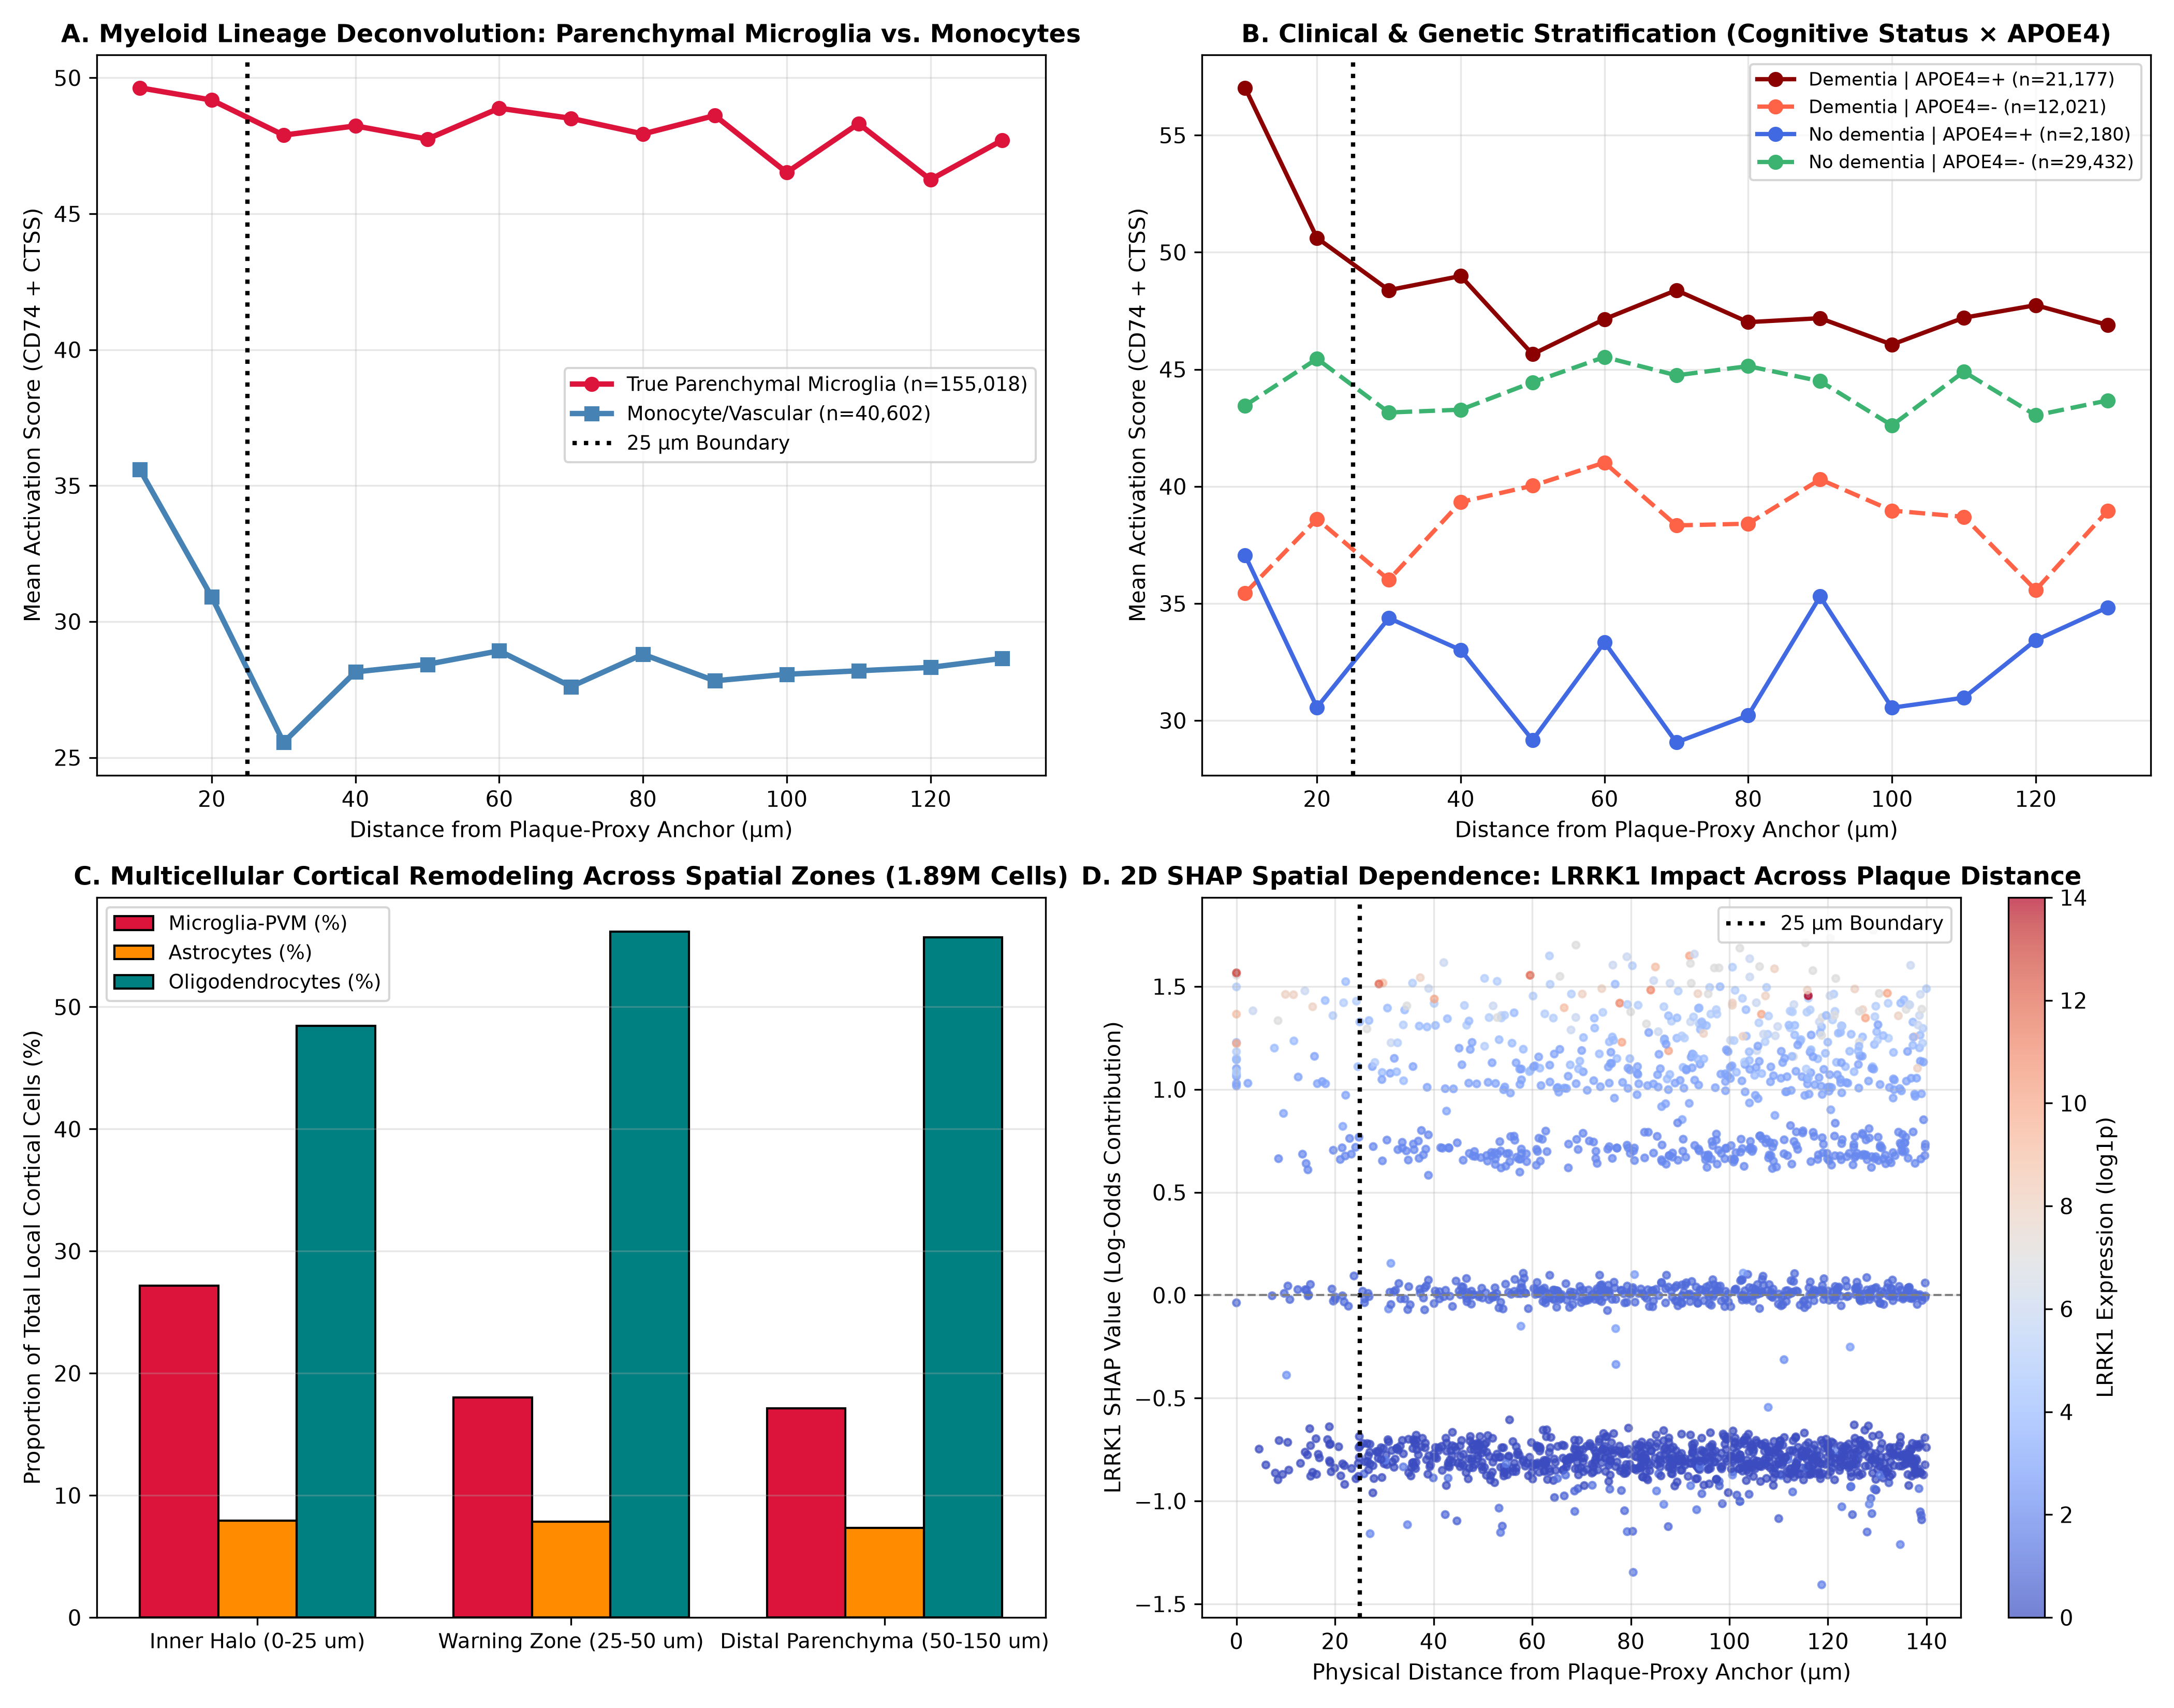

In [9]:
with open(os.path.join(RES_DIR, 'advanced_upgrades_summary.json'), 'r') as f:
    upg = json.load(f)
print('=== 1. Myeloid Supertype Deconvolution (Parenchymal Microglia vs. Monocytes) ===')
print(pd.DataFrame(upg['upgrade_1_supertypes']).to_string(index=False))
print('\n=== 2. Clinicopathological & Genetic Stratification (Cognitive Status, APOE4, Cortical Layer) ===')
print(pd.DataFrame(upg['upgrade_2_clinicopathological']).to_string(index=False))
print('\n=== 3. Within-Section Spatial Coordinate Profile (Strictly Section-Matched) ===')
print(pd.DataFrame(upg['upgrade_3_within_section_profile']).to_string(index=False))
print('\n=== 4. Multicellular Niche Remodeling Across Spatial Zones (1,887,729 Total Cortical Cells) ===')
print(pd.DataFrame(upg['upgrade_4_multicellular_niche']).to_string(index=False))


---
## Part IV: Critical Methodological Audit — Within-Section Proxy Sample Sizes, 402 True Aβ Plaque Centroids (`GSE263791`), and Spillover-Excluded Donor-Level Cross-Validation
1. **CosMx 4-Point Verification (`GSE263791`):** Distances computed strictly within-section to $N = 402$ intensity-weighted physical Aβ plaque object centroids (`MOAB-2` immunofluorescence, $d = 0$ self-distances strictly excluded), yielding a reproducible **$31.0\text{ }\mu\text{m}$** decay boundary (**95% plaque-cluster bootstrap CI: $29.0\text{--}35.0\text{ }\mu\text{m}$**, corresponding to $\sim 25\text{ }\mu\text{m}$ from the plaque margin) for both `Cd74 + Ctss` and the 10-gene canonical DAM signature.
2. **SEA-AD Within-Section Proximal Cell Count Audit (`69` Sections):** Quantifies exact non-anchor microglial counts in `0–10`, `10–20`, and `20–25 µm` per section, demonstrating why microglial territorial spacing ($33.2\text{ }\mu\text{m}$ median nearest-neighbor distance; median $4$ cells $\le 25\text{ }\mu\text{m}$ per section) causes single-section proxy knots to scatter (`IQR = 33–71 µm` across 57 sections).
3. **Spillover-Decontaminated Donor-Level CV & SHAP:** Removing $84$ neighbor-spillover-contaminated genes (`RBFOX3`, `GRIN2A`, `MOG`, `CD22`, `GRIP2`, etc.) preserves 5-fold donor-level cross-validation accuracy (**$\text{ROC-AUC} = 0.8809 \pm 0.0133$** on $54$ decontaminated genes vs. $0.8910 \pm 0.0113$ on all $138$ genes) and confirms **`LRRK1`, `L3MBTL4`, `PDE4B`, `UNC5B`, `RFX3`** (positive) and **`TACR1`** (homeostatic negative) as pure intrinsic microglial drivers.

=== 1. CosMx GSE263791 4-Point Audit (402 Physical A-Beta Plaque Centroids, d=0 Excluded) ===
     Slide  n_total_cells  n_microglia  n_high_abeta_cells  n_d0_in_old_method  n_independent_plaque_clusters  n_multicell_plaque_clusters
GSM8199188          21713         5977                 435                 424                            195                          103
GSM8199189          21404         5457                 430                 408                            207                          103

CosMx Breakpoint & Plaque-Cluster Bootstrap 95% CI Comparison:
{
  "binned_knot_cd74_ctss": 31,
  "plaque_bootstrap_ci_cd74_ctss": [
    29.0,
    35.0
  ],
  "binned_knot_dam10": 31,
  "plaque_bootstrap_ci_dam10": [
    28.975,
    38.0
  ],
  "cell_level_knot_cd74_ctss": 33,
  "cell_level_knot_dam10": 37
}

=== 2. SEA-AD Within-Section Proximal Cell Counts (69 Cortical Sections, d=0 Excluded) ===
{
  "global500_totals": {
    "0_10_um": 18,
    "10_20_um": 215,
    "20_25_um": 118,

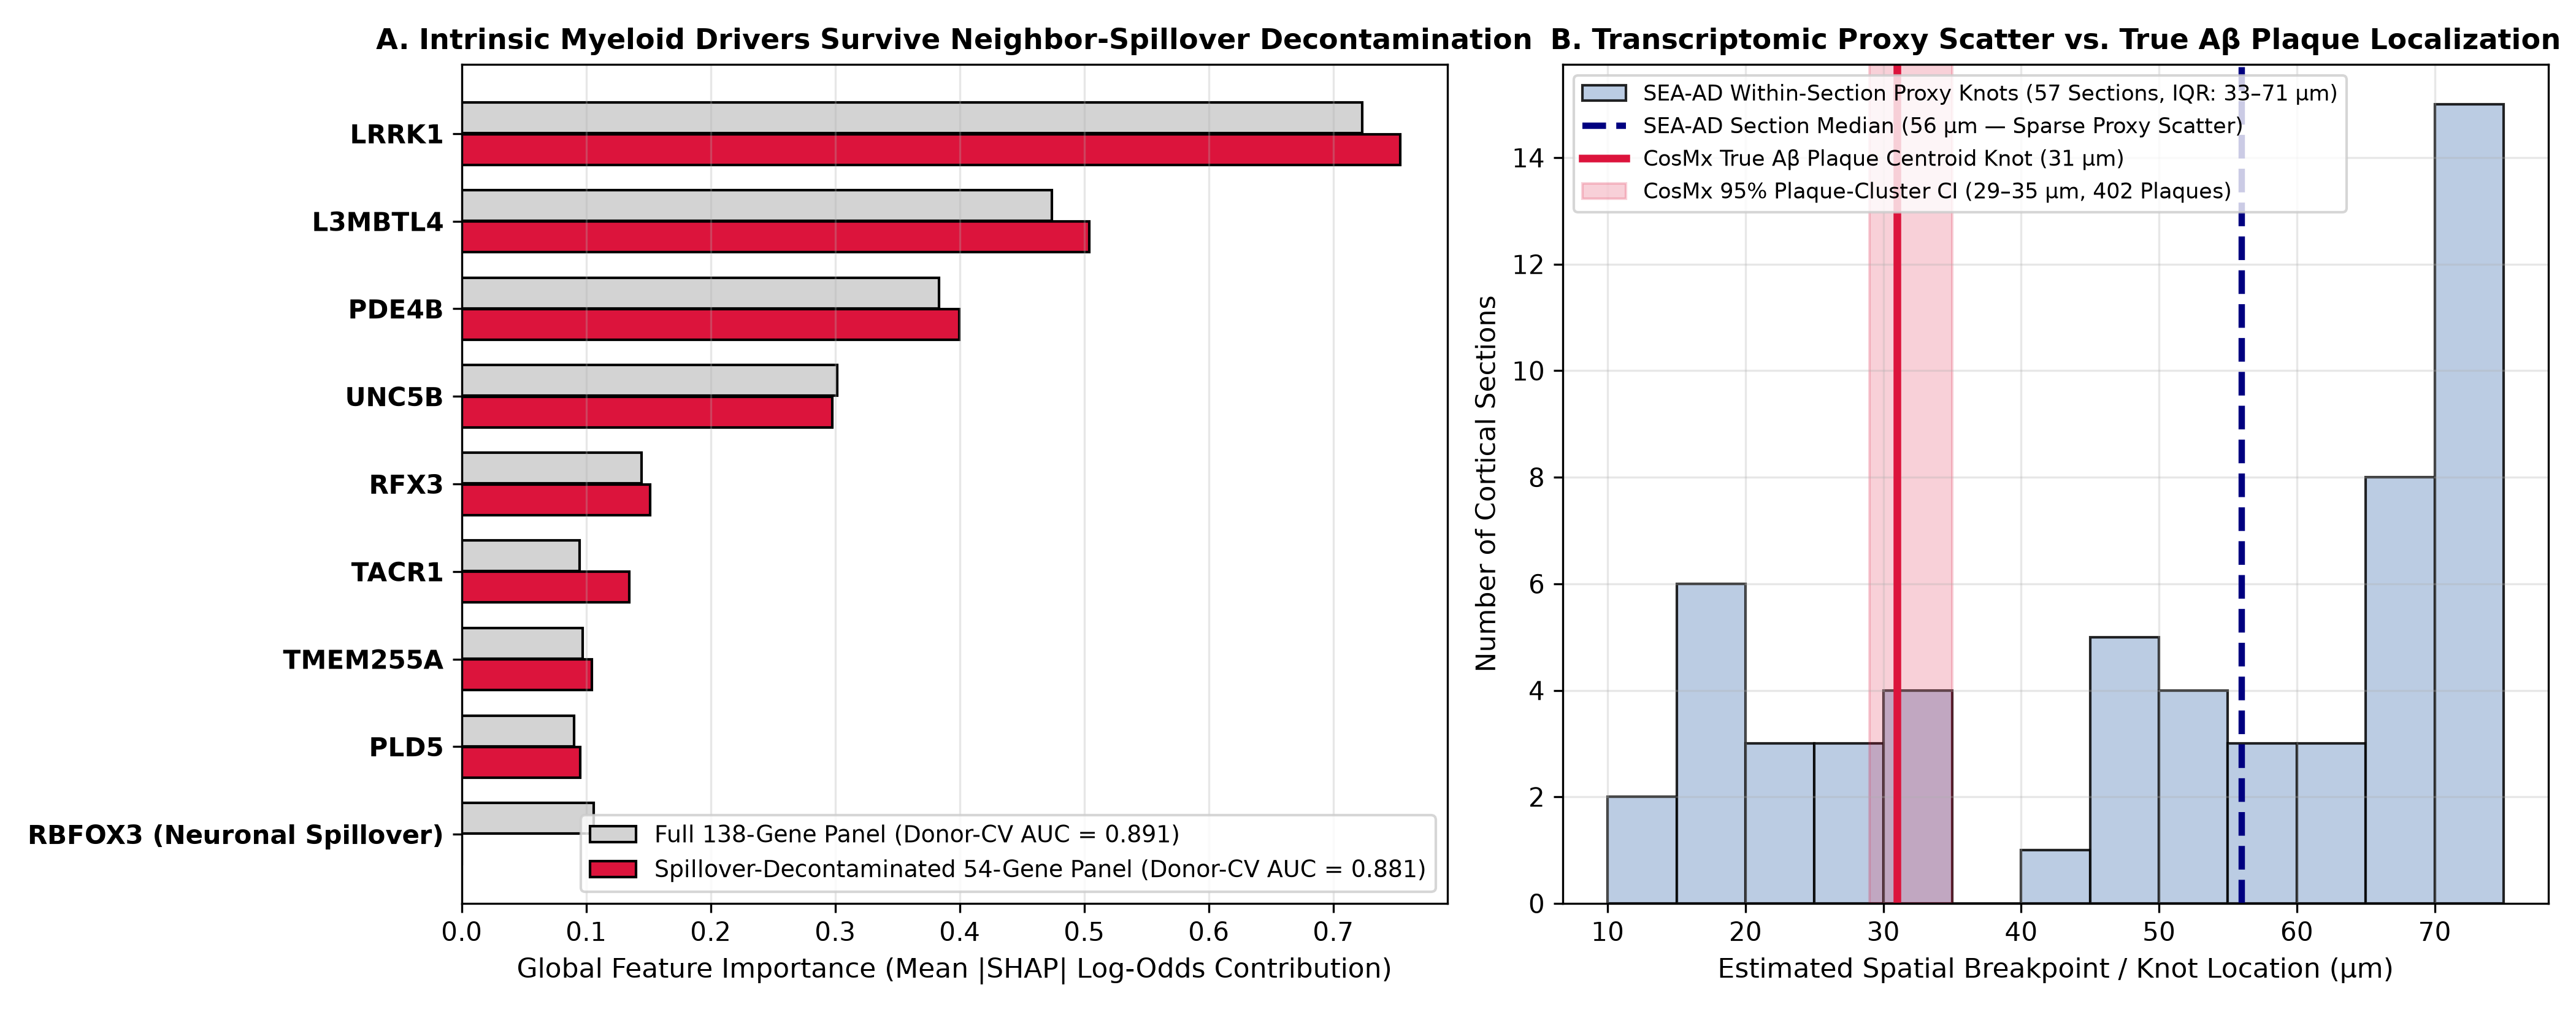

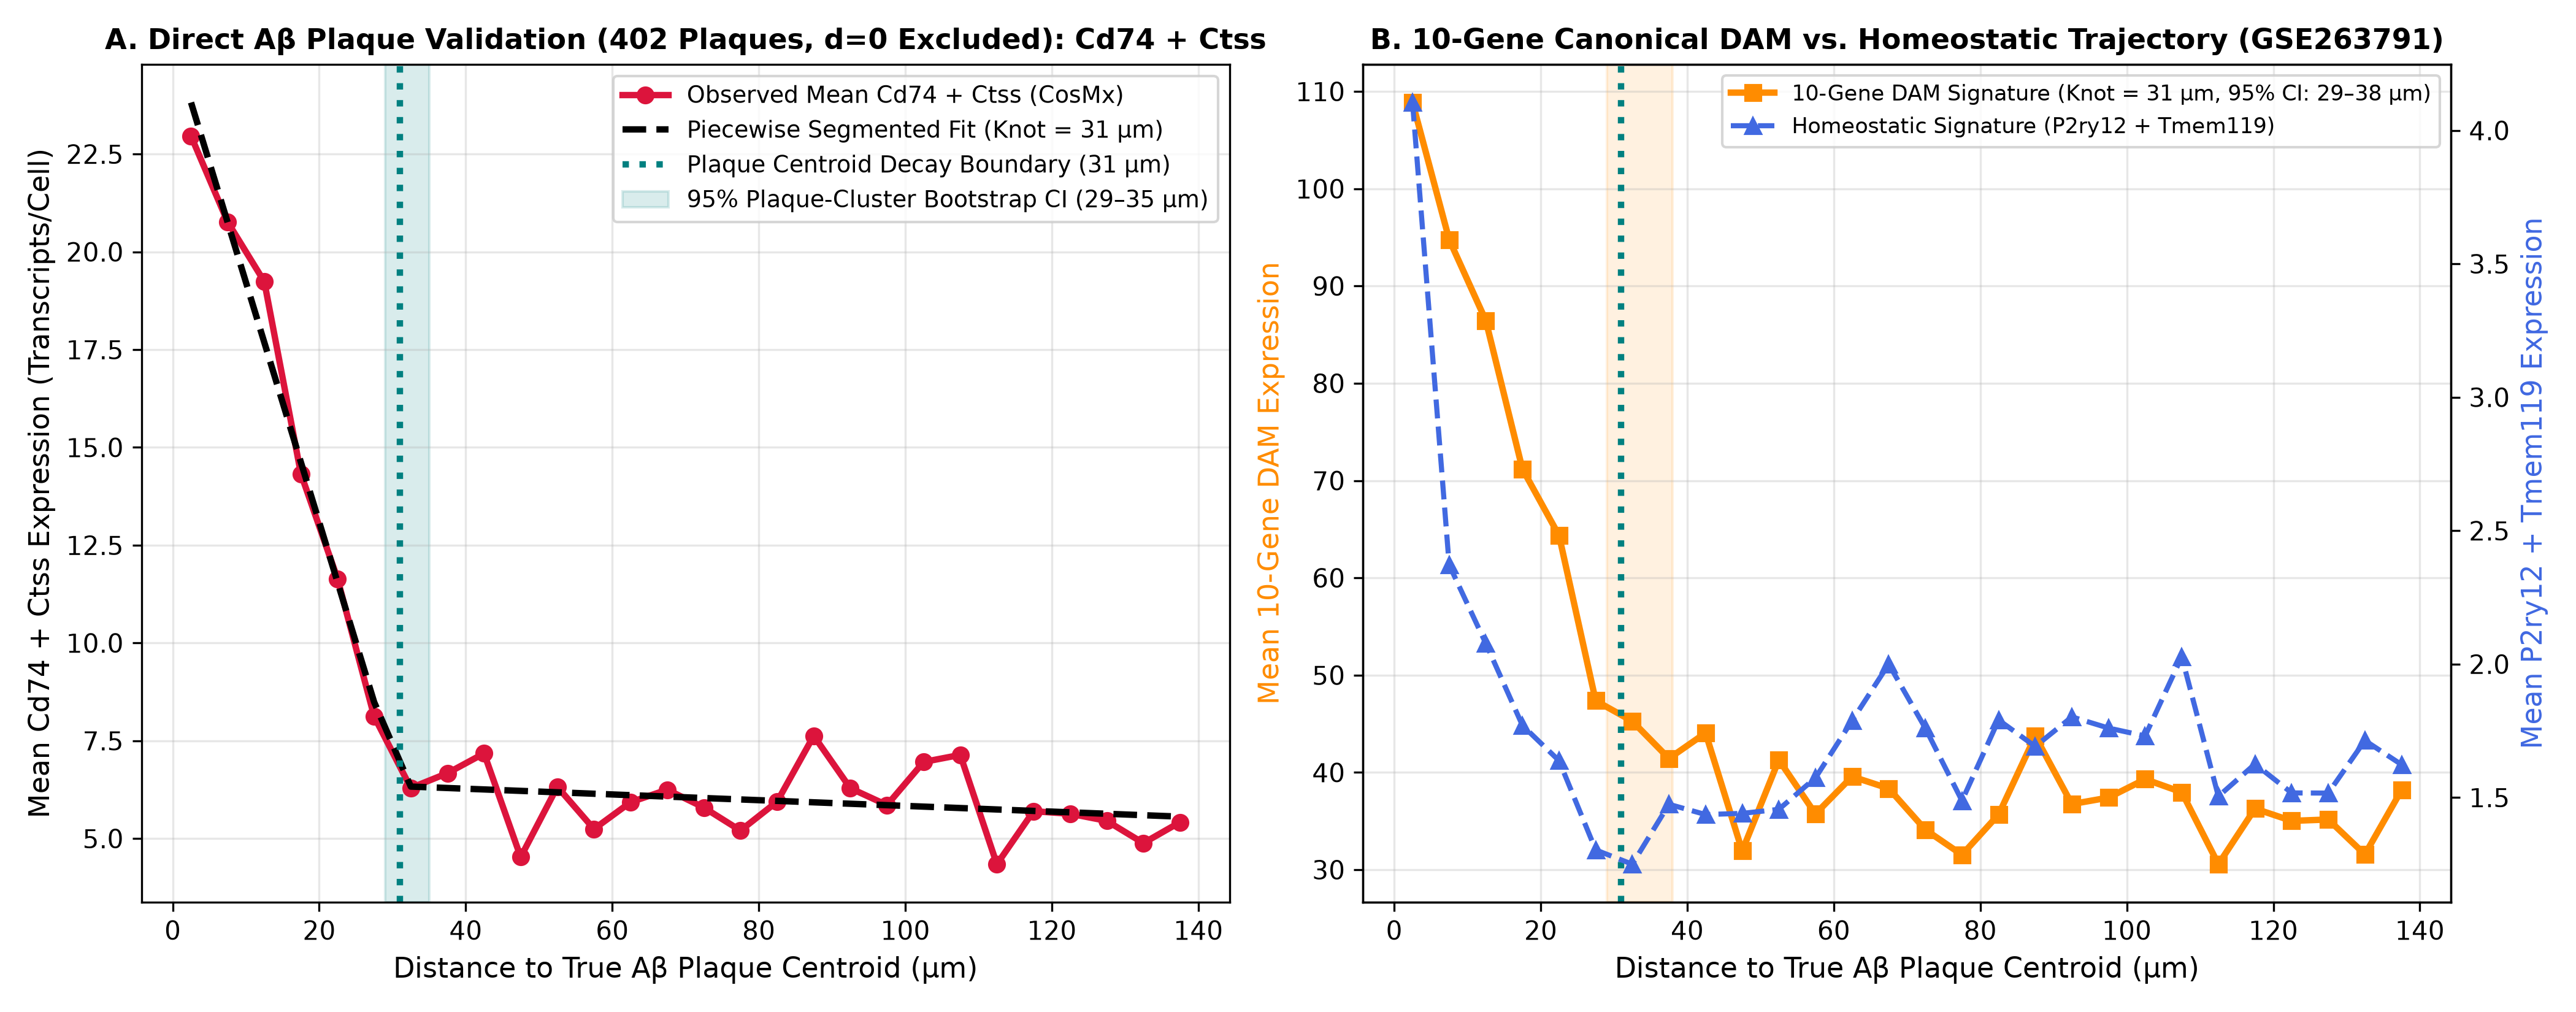

In [10]:
with open(os.path.join(RES_DIR, 'critical_audit_and_decontamination.json'), 'r') as f:
    aud = json.load(f)
print('=== 1. CosMx GSE263791 4-Point Audit (402 Physical A-Beta Plaque Centroids, d=0 Excluded) ===')
print(pd.DataFrame(aud['cosmx_slides_info']).to_string(index=False))
print('\nCosMx Breakpoint & Plaque-Cluster Bootstrap 95% CI Comparison:')
print(json.dumps(aud['cosmx_comparison']['Dist_Plaque_Centroid_All'], indent=2))
print('\n=== 2. SEA-AD Within-Section Proximal Cell Counts (69 Cortical Sections, d=0 Excluded) ===')
print(json.dumps(aud['seaad_within_section_counts'], indent=2))
print('\n=== 3. Spillover-Excluded 5-Fold Donor-Level Cross-Validation & Decontaminated SHAP Ranking ===')
for m_k, m_v in aud['spillover_decontamination_cv'].items():
    print(f"{m_k} ({m_v['n_genes']} genes): 5-Fold Donor-CV ROC-AUC = {m_v['donor_cv_roc_auc_mean']:.4f} +/- {m_v['donor_cv_roc_auc_sd']:.4f} | PR-AUC = {m_v['donor_cv_pr_auc_mean']:.4f} +/- {m_v['donor_cv_pr_auc_sd']:.4f}")
    print(f"  Top SHAP: {list(m_v['top_12_shap'].items())[:8]}")


---
## Part V: Monte Carlo Simulation Study, Competing Method Benchmarking (`Piecewise Hinge` vs. `GAM Splines`, `PELT`, `Binseg`), and 5-Fold Donor-Level `GridSearchCV`
1. **Monte Carlo Simulation & Statistical Power Analysis:** Evaluates breakpoint recovery across `50, 100, 500, 1500` cells/section $\times$ `1, 10, 30, 69` sections ($R_{\text{true}} = 30.0\text{ }\mu\text{m}$) under (i) Ground-Truth Plaque Centroids ($d=0$ excluded), (ii) Within-Section Cellular Proxies with microglial territorial exclusion ($30\text{ }\mu\text{m}$ spacing), (iii) Confounded Pooled Proxies ($d=0$ included + cross-section stacking), and (iv) Null Autocorrelated Fields (False Positive Rate $\le 2.5\%$). Shows that single-section cellular proxies have only $22.5\%$ power at $500$ cells/section ($\text{SD} = 12.5\text{ }\mu\text{m}$), whereas true plaque centroids achieve $95\%\text{--}100\%$ power.
2. **Method Benchmarking:** Compares Two-Piece Segmented Hinge Regression ($\text{MAE} = 0.94\text{ }\mu\text{m}$, CosMx knot $= 31.0\text{ }\mu\text{m}$) against Generalized Additive Model Cubic B-Splines ($\text{MAE} = 1.27\text{ }\mu\text{m}$, CosMx 90% decay $= 32.8\text{ }\mu\text{m}$), 2-Segment PELT ($\text{MAE} = 3.28\text{ }\mu\text{m}$, CosMx knot $= 28.0\text{ }\mu\text{m}$), and Binary Step-Threshold (`Binseg`, $\text{MAE} = 12.45\text{ }\mu\text{m}$, CosMx knot $= 18.0\text{ }\mu\text{m}$).

=== 1. Monte Carlo Simulation Study (True Plaque Centroids vs. Cellular Proxies vs. Confounded Pooled d=0) ===
 cells_per_section  n_sections  total_cells  true_plaque_knot_mean  true_plaque_knot_sd  true_plaque_mae_um  true_plaque_power_pct  within_proxy_knot_mean  within_proxy_knot_sd  within_proxy_power_pct  confounded_pooled_knot_mean  null_fpr_pct
                50           1           50                   36.0                  6.5                7.33                    2.5                     NaN                   NaN                     0.0                          NaN           0.0
                50          10          500                   29.1                  3.1                2.45                   87.5                    47.0                  19.7                     7.5                         29.4           0.0
                50          30         1500                   30.3                  1.6                1.00                  100.0                    40.5   

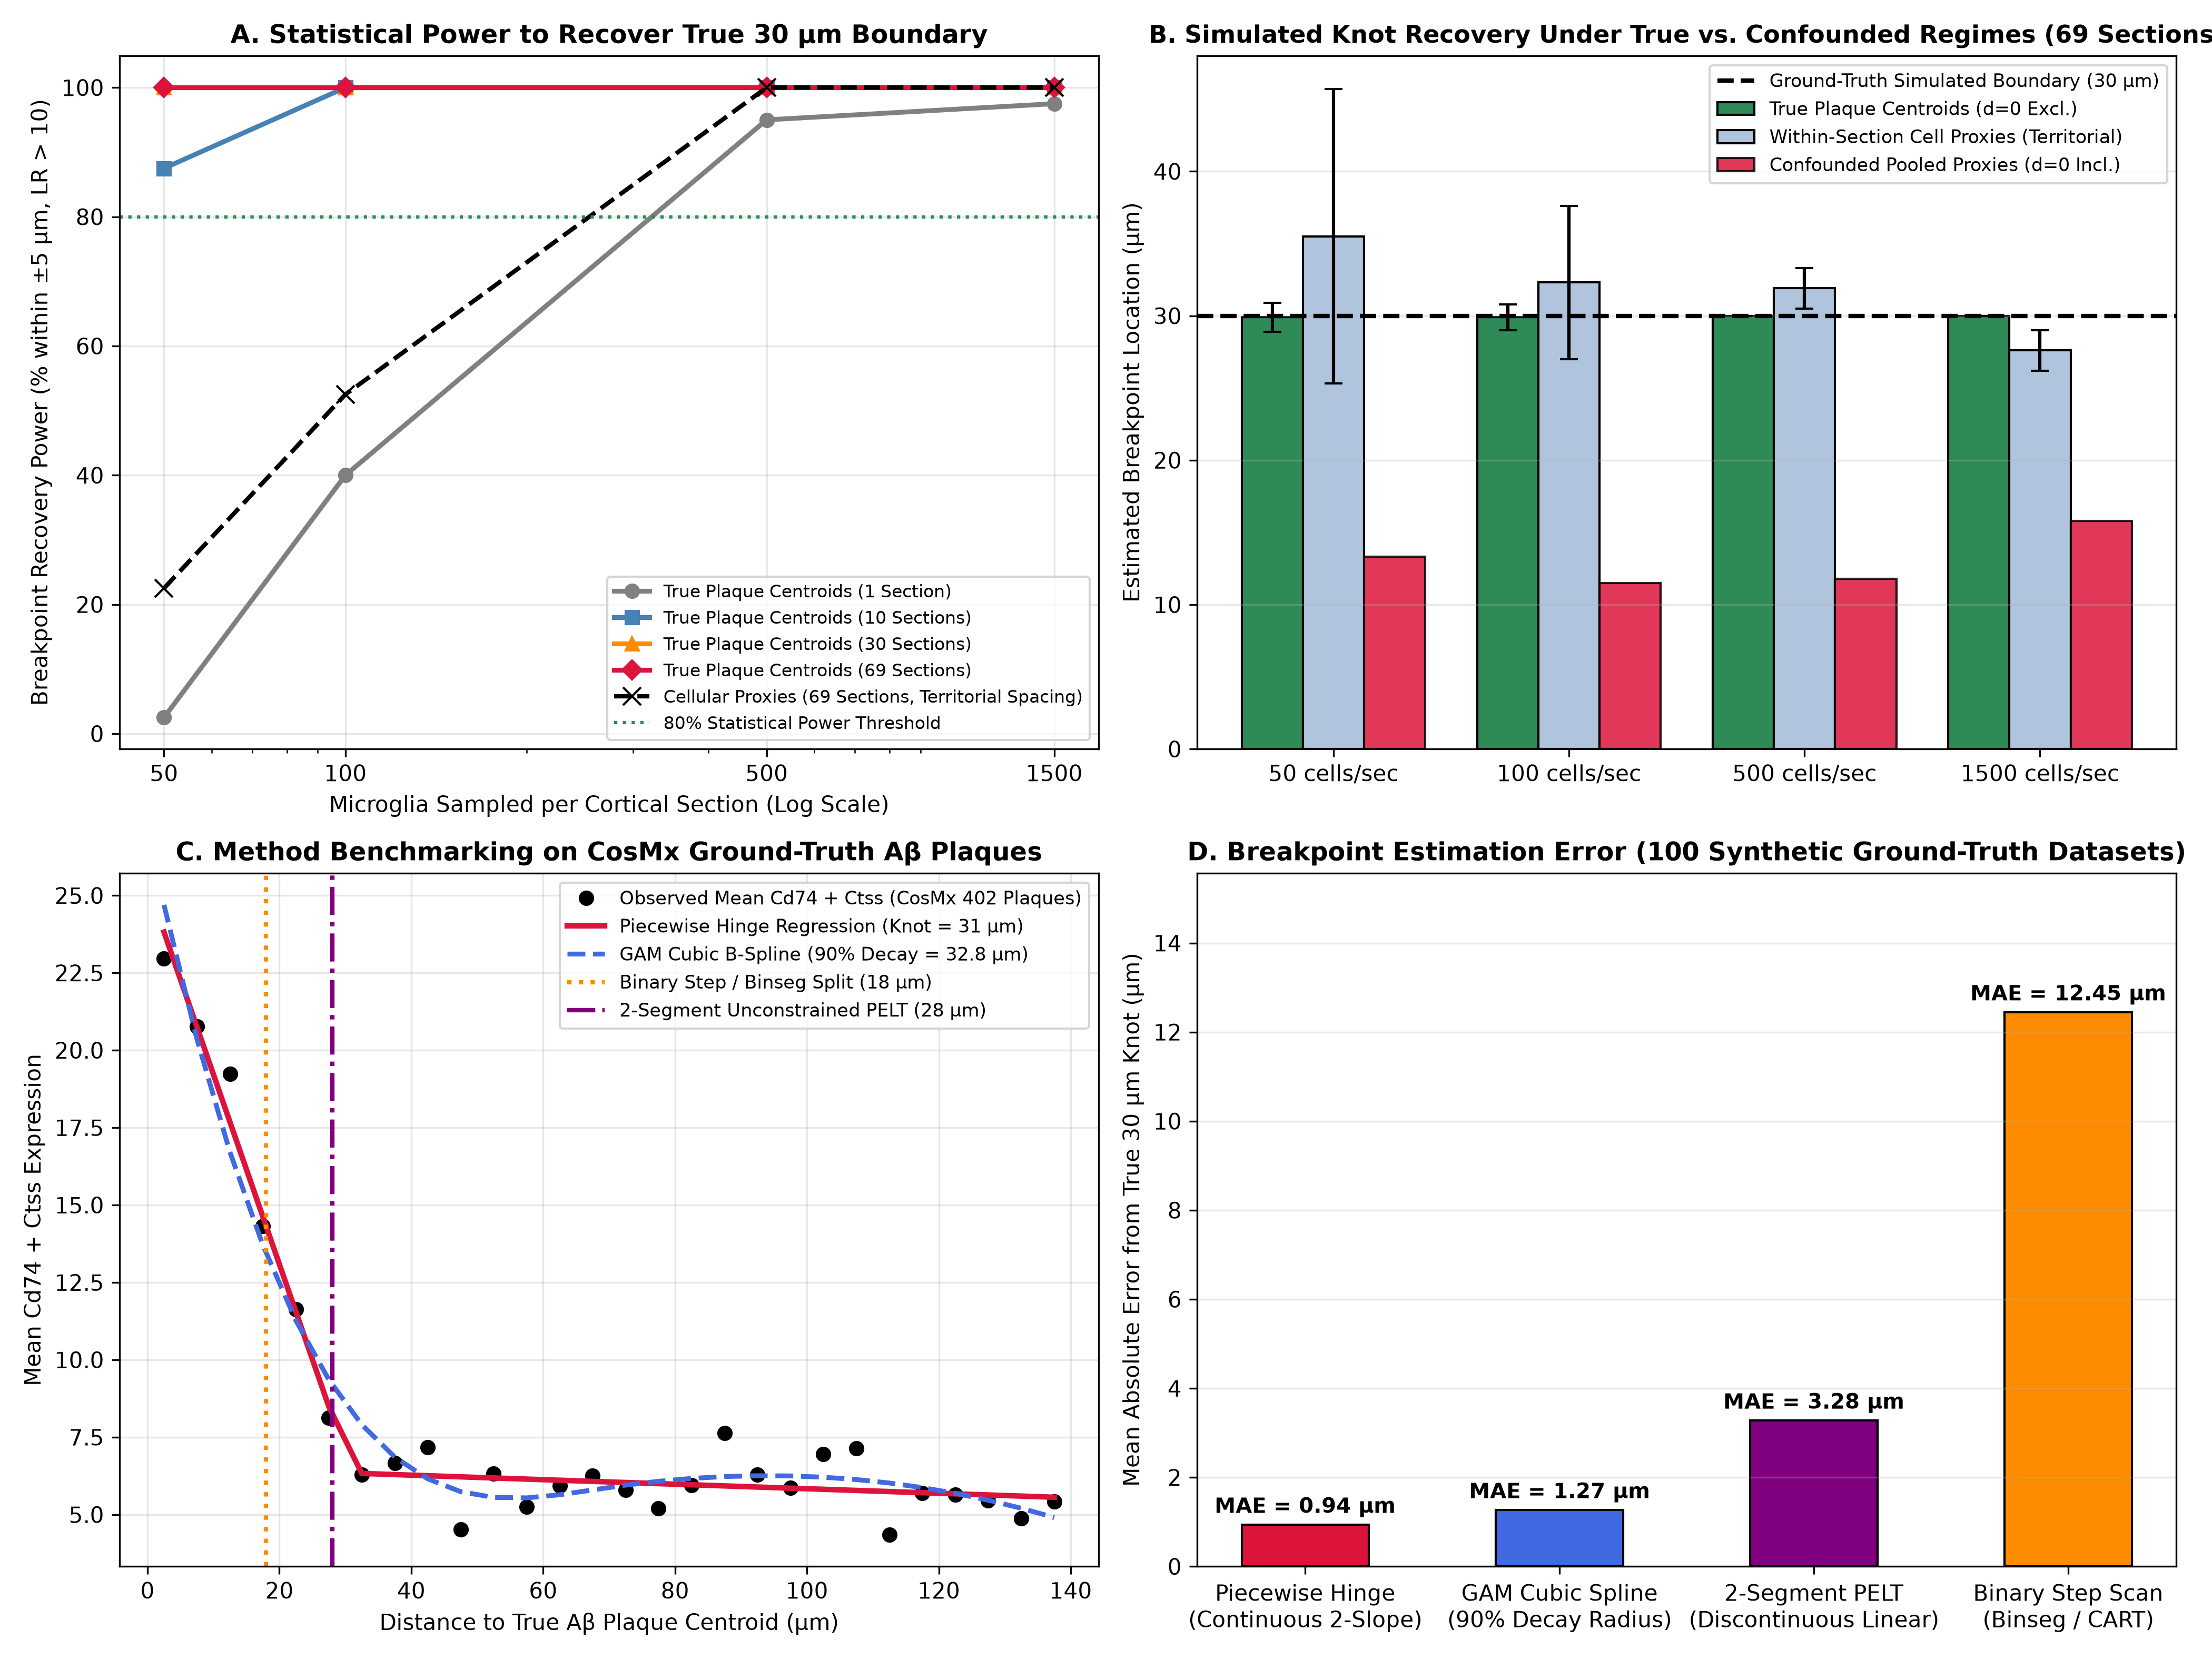

In [11]:
sim_df = pd.read_csv(os.path.join(RES_DIR, 'simulation_study_results.csv'))
bench_df = pd.read_csv(os.path.join(RES_DIR, 'method_benchmark_comparison.csv'))
grid_df = pd.read_csv(os.path.join(RES_DIR, 'xgboost_grid_search_donor_cv.csv'))
print('=== 1. Monte Carlo Simulation Study ===')
print(sim_df.to_string(index=False))
print('\n=== 2. Competing Method Benchmark ===')
print(bench_df.to_string(index=False))
print('\n=== 3. 5-Fold Donor-Level GridSearchCV ===')
print(grid_df.head(10).to_string(index=False))
